In [137]:
import re
import regex
assert "regex" in str(regex.compile("(test){e<=1}"))
import pandas as pd
import os
import numpy as np
pd.set_option("display.max_colwidth", 40)
from nltk.corpus import stopwords
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import classification_report, accuracy_score
from sklearn.metrics import confusion_matrix, f1_score, cohen_kappa_score
from sentence_transformers import SentenceTransformer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import cross_val_predict, GridSearchCV, cross_val_score
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt
from pathlib import Path
project_dir = Path().resolve()
os.chdir(project_dir)

In [138]:
folder_path = "Text_Files"

rows = []

for filename in os.listdir(folder_path):
    if filename.endswith(".txt"):
        file_path = os.path.join(folder_path, filename)
        with open(file_path, "r", encoding="utf-8") as f:
            text = f.read() 
        rows.append({
            "filename": filename,
            "text": text
        })

df = pd.DataFrame(rows)

print(f"{len(df)} documents read")

97 documents read


## Extracting Rough Snippets

In [139]:
pattern1 = re.compile(
      r"Dear.*?(?:Sincer[a-z]{1,5}\b|Thank you for [Pp]art|Respetuosamente)",
      re.DOTALL)

pattern2 = re.compile(
      r"(?:\n|\A)\s*"
      r"Via[^\n]*\n"
      r"(?:\s*\n){0,3}"
      r"(?:\s*\S+(?:\s+\S+){0,5}\s*\n)?"
      r"(?:\s*\n){0,3}"
      r"(?:\s*\d{3,5}(?:\s+\d{3,5})+\s*\n)?\s*"
      r"(?:\s*\n){0,3}"
      r"(?:\s*\S+(?:\s+\S+){0,5}\s*\n)?"
      r"(?:\s*\n){0,3}"
      r"(?:\s*\S+(?:\s+\S+){0,5}\s*\n)?"
      r"(?:\s*\n){0,3}"
      r"(?:\s*\S+(?:\s+\S+){0,5}\s*\n)?"
      r"(?:\s*\n){0,3}"
      r"(?:[^\w\s]?Re[:;]\s*)?"
      r"(?:CPC\s*#?\s*|[^\w\s]#\s*)?"
      r"\d{2,3}-\d[\d!\])}]"
      r".*?"
      r"(?:Sincer[a-z]{1,5}\b|Thank you for [Pp]art|Respetuosamente)",
      re.DOTALL
  )

pattern3 = re.compile(
      r"(?:\n|\A)\s*"
      r"To Fi[lt]e\s*\n"                            
      r"(?:\s*\n){0,3}"
      r"(?:\s*\S+(?:\s+\S+){0,5}\s*\n)?"           
      r"(?:\s*\n){0,2}"
      r"(?:\s*\S+(?:\s+\S+){0,5}\s*\n)?"           
      r"(?:\s*\n){0,2}"
      r"(?:\s*\S+(?:\s+\S+){0,5}\s*\n)?"           
      r"(?:\s*\n){0,3}"
      r"(?:[^\w\s]?Re[:;]\s*)?"                     
      r"(?:CPC\s*#?\s*|[^\w\s]#\s*)?"              
      r"\d{2,3}-\d[\d!\])}]"                        
      r".*?"
      r"(?:Sincer[a-z]{1,5}\b|Thank you for [Pp]art|Respetuosamente)",
      re.DOTALL
  )

  # pattern4: catches 2018 and 2025 batch formats where the letter header is
  # just a date line followed directly by "Re: CPC# NNN-NN" — no Via, To File,
  # or Dear. Runs last so it never steals from pattern1/2/3.
pattern4 = re.compile(
      r"(?:\n|\A)\s*"
      r"(?:[^\w\s]?Re[:;]\s*)" 
      r"(?:CPC\s*#?\s*)?"
      r"\d{2,3}-\d[\d!\])}]"
      r".*?"
      r"(?:Sincer[a-z]{1,5}\b|Thank you for [Pp]art|Respetuosamente)",
      re.DOTALL
  )

pattern5 = re.compile(
    r"(?:\n|\A)\s*"
    r"Via[^\n]*\n"
    r"\n"
    r"(?:[^\n]*\n\s*\n){1,3}"
    r"(?:Re[:;]\s*)?"
    r"(?:CPC\s*#?\s*)?"
    r"\d{2,4}-\d{2}"
    r".*?"
    r"(?:Sincer[a-z]{1,5}\b|Thank you for [Pp]art|Respetuosamente)",
    re.DOTALL
)

In [140]:
WINDOW = 100

def add_window(text, start, end, window=100):
    """Add a window to the matched text."""
    start_ctx = max(0, start - window)
    end_ctx = min(len(text), end + window)
    return text[start_ctx:end_ctx]

def merge_spans(spans):
    if not spans:
        return []
    spans = sorted(spans)
    merged = [list(spans[0])]
    for s, e in spans[1:]:
        if s <= merged[-1][1]:
            merged[-1][1] = max(merged[-1][1], e)
        else:
            merged.append([s, e])
    return merged

def subtract_spans(text, spans):
    spans = merge_spans(spans)
    leftovers = []
    prev = 0
    for s, e in spans:
        if prev < s:
            leftovers.append(text[prev:s])
        prev = e
    if prev < len(text):
        leftovers.append(text[prev:])
    return leftovers

def overlaps(span, used_spans):
    s1, e1 = span
    for s2, e2 in used_spans:
        if not (e1 <= s2 or s1 >= e2):
            return True
    return False

rows = []

for _, row in df.iterrows():
    filename = row["filename"]
    text = row["text"]
    used_spans = []

    # PATTERN 1
    for m in pattern1.finditer(text):
        start, end = m.start(), m.end()
        if overlaps((start, end), used_spans):
            continue
        used_spans.append((start, end))
        rows.append({
            "filename": filename,
            "pattern": "pattern1",
            "snippet": add_window(text, start, end, WINDOW)
        })

    # PATTERN 2
    for m in pattern2.finditer(text):
        start, end = m.start(), m.end()
        if overlaps((start, end), used_spans):
            continue
        used_spans.append((start, end))
        rows.append({
            "filename": filename,
            "pattern": "pattern2",
            "snippet": add_window(text, start, end, WINDOW)
        })
        
    # PATTERN 3
    for m in pattern3.finditer(text):
        start, end = m.start(), m.end()
        if overlaps((start, end), used_spans):
            continue
        used_spans.append((start, end))
        rows.append({
            "filename": filename,
            "pattern": "pattern3",
            "snippet": add_window(text, start, end, WINDOW)
        })
        
    # PATTERN 4 
    for m in pattern4.finditer(text): 
        start, end = m.start(), m.end() 
        if overlaps((start, end), used_spans): 
            continue 
        used_spans.append((start, end)) 
        rows.append({ 
            "filename": filename, 
            "pattern": "pattern4", 
            "snippet": add_window(text, start, end, WINDOW) 
        })
    
    # PATTERN 5 
    leftover_chunks = subtract_spans(text, used_spans)
    final_unmatched_chunks = []
    for chunk in leftover_chunks:
        if "COMPLAINT" in chunk:
            chunk_used_spans = []
            for m in pattern5.finditer(chunk):
                start, end = m.start(), m.end()
                chunk_used_spans.append((start, end))
                rows.append({
                    "filename": filename,
                    "pattern": "pattern5",
                    "snippet": add_window(chunk, start, end, WINDOW)
                })
            chunk_leftovers = subtract_spans(chunk, chunk_used_spans)
            final_unmatched_chunks.extend(chunk_leftovers)
        else:
            final_unmatched_chunks.append(chunk)

    # UNMATCHED TEXT
    for chunk in final_unmatched_chunks:
        chunk = chunk.strip()
        if chunk:
            rows.append({
                "filename": filename,
                "pattern": "unmatched",
                "snippet": chunk
            })

df_combined = pd.DataFrame(rows)
df_combined["snippet"] = df_combined["snippet"].astype(str)

## Dealing with Unmatched Chunks

In [141]:
df_dear_chief = df_combined[df_combined["snippet"].str.contains(r"\bdear\s+(chief|interim)\b", case=False, na=False, regex=True)]
# df_dear_chief.to_csv("chief_letters.csv", index=False)

unmatched_text = df_combined.loc[df_combined["pattern"] == "unmatched"]
# unmatched_text.to_csv("unmatched.csv", index=False)

df_unmatched_700 = unmatched_text[unmatched_text["snippet"].str.len() > 700]
df_unmatched_700 = df_unmatched_700.drop(index=df_dear_chief.index, errors="ignore")
df_unmatched_700 = df_unmatched_700[
    ~(df_unmatched_700["snippet"].str.contains(r"\bAGENDA\b|teleconference|INTERNAL AFFAIRS", na=False) &
      ~df_unmatched_700["snippet"].str.contains(r"Sincerely", case=False, na=False))
]
df_unmatched_complaint = df_unmatched_700[df_unmatched_700["snippet"].str.contains(r"COMPLAINT", na=False, regex=True)]
print(len(df_unmatched_complaint))
df_unmatched_complaint = df_unmatched_complaint[~df_unmatched_complaint["snippet"].str.contains(r"INTERNAL AFFAIRS", na=False, regex=True)]
print(len(df_unmatched_complaint))

df_combined = df_combined.drop(df_dear_chief.index.union(unmatched_text.index))

1
0


/var/folders/2l/nhkr05_11xl7646nkk74q5640000gn/T/ipykernel_88011/1720576531.py:1: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  df_dear_chief = df_combined[df_combined["snippet"].str.contains(r"\bdear\s+(chief|interim)\b", case=False, na=False, regex=True)]


In [142]:
print(len(df_unmatched_complaint))

0


## Capturing Case Numbers

In [143]:
df_combined["case_number"] = df_combined["snippet"].str.extract(r"CF?PC\s*#?4?\s*([0-9]+-[0-9]+)", flags=re.IGNORECASE)
df_combined["case_number_again"] = (                                                           
      df_combined["snippet"]                                                                     
      .str.extract(                                                                              
          r"(?:"
          r"[^\w\s]?Re[:;]\s*(?:CF?PC\s*#?4?\s*)?"                                               
          r"|CF?PC\s*#?4?\s*"                                                                    
          r"|[^\w\s]#\s*"                                                                      
          r")"                                                                                   
          r"([0-9]{2,3}-[0-9][\d!\])}])",                                                      
          flags=re.IGNORECASE                                                                    
      )[0]
      .str.replace(r"[\]!)}]$", "1", regex=True)                                                 
  )

df_combined["casenum_disagreement"] = np.where(
    (
        df_combined["case_number_again"].notna() &
        df_combined["case_number"].notna() &
        (df_combined["case_number"] != df_combined["case_number_again"])
    ),
    df_combined["case_number_again"],
    pd.NA
)


In [144]:
# Sole Persisting Case Number OCR issue.
df_combined.loc[3104, "case_number"] = "251-21"

In [145]:
print(df_combined[df_combined["case_number"].isna() 
      & df_combined["case_number_again"].isna()])
print(len(df_combined[df_combined["casenum_disagreement"].notna()]))

Empty DataFrame
Columns: [filename, pattern, snippet, case_number, case_number_again, casenum_disagreement]
Index: []
8


In [146]:
casenum_mask = (
    df_combined["case_number"].isna() |
    df_combined["casenum_disagreement"].notna()
)
df_combined.loc[casenum_mask, "case_number"] = df_combined.loc[casenum_mask, "case_number_again"]

df_combined = df_combined.drop(columns = ["case_number_again", "casenum_disagreement"])

## Capturing Letter Date, Incident Date, Complaint Date

In [147]:
date_pattern = (
    r"(?:January|February|March|April|May|June|July|August|September|October|November|December)"
    r"\s+\d{1,2}"
    r"(?:,\s*\d{4})?")

DEAR = r"(?:Dear|Re:){e<=1}"

letter_date_pattern = (
    r"((?:January|February|March|April|May|June|July|August|September|October|November|December)"
    r"\s+\d{1,2},\s*\d{4})"
)

def extract_letter_date(text):
    if not isinstance(text, str):
        return None

    split = regex.search(
        r"^(.*?)(?:Dear|Re:)",
        text,
        flags=regex.IGNORECASE | regex.DOTALL
    )

    if split:
        m = regex.search(letter_date_pattern, split.group(1))
        if m:
            return m.group(0)

    lt = regex.search(
        r"(Letter\s*to){e<=1}.{0,50}",
        text,
        flags=regex.IGNORECASE | regex.DOTALL
    )

    if lt:
        m = regex.search(letter_date_pattern, lt.group(0))
        if m:
            return m.group(0)

    return None

df_combined["letter_date"] = df_combined["snippet"].apply(extract_letter_date)


date_pattern = (
    r"(?:"
    r"(?:January|February|March|April|May|June|July|August|September|October|November|December)"
    r"\s+\d{1,2},\s+\d{4}"
    r"|"
    r"\d{1,2}[/-]\d{1,2}[/-]\d{2,4}"
    r")"
)

incident_date_pattern = (
    r"(?:occurred|took\s+place)"
    r".{0,75}?"
    r"(?:on(?:\s+or\s+about)?\s+)?"
    + f"({date_pattern})"
)

df_combined["incident_date"] = df_combined["snippet"].str.extract(
    incident_date_pattern,
    flags=re.I
)

In [148]:
percent_missing = df_combined.isnull().mean() * 100
print(percent_missing)

filename          0.000000
pattern           0.000000
snippet           0.000000
case_number       0.000000
letter_date       4.156234
incident_date    62.994492
dtype: float64


In [149]:
ed_1_complaint_date_pattern = re.compile(
    r"dear(?:\s+\S+){0,10}?\s+"
    r"("
    r"(?:January|February|March|April|May|June|July|August|September|October|November|December)"
    r"\s+\d{1,2}"
    r"(?:,\s*\d{4})?"
    r")",
    re.IGNORECASE
)
df_combined["complaint_date_1"] = df_combined["snippet"].str.extract(ed_1_complaint_date_pattern)

ed_1_complaint_date_pattern_2 = re.compile(
    rf"(?:"
    rf"({date_pattern})\s+against"
    rf"|"
    rf"against(?:\s+\S+){{0,10}}?\s+on\s+({date_pattern})"
    rf")",
    re.IGNORECASE
)

matches = df_combined["snippet"].str.extract(ed_1_complaint_date_pattern_2)
df_combined["complaint_date_2"] = matches[0].combine_first(matches[1])
df_combined["complaint_date"] = df_combined["complaint_date_1"].combine_first(df_combined["complaint_date_2"])

df_combined["disagreement"] = np.where(
    (
        df_combined["complaint_date_1"].notna() &
        df_combined["complaint_date_2"].notna() &
        (df_combined["complaint_date_1"] != df_combined["complaint_date_2"])
    ),
    df_combined["complaint_date_2"],
    pd.NaT
)

## Re-Indexing

In [150]:
df_combined["id_pre"] = df_combined.index

In [151]:
df_combined = df_combined.reset_index(drop=True)
df_combined["id_post"] = df_combined.index
df_combined = df_combined[["id_post"] + [c for c in df_combined.columns if c != "id_post"]]

## Incident and Complaint Date Capture Pt.2

In [152]:
percent_missing = df_combined.isnull().mean() * 100
print(percent_missing)

id_post              0.000000
filename             0.000000
pattern              0.000000
snippet              0.000000
case_number          0.000000
letter_date          4.156234
incident_date       62.994492
complaint_date_1    81.622434
complaint_date_2    85.277917
complaint_date      71.206810
disagreement        98.948423
id_pre               0.000000
dtype: float64


In [153]:
def normalize_text(text):
    text = text.lower()
    text = re.sub(r"\s+", " ", text)
    text = text.strip()
    return text

In [154]:
mask = df_combined["incident_date"].isna()

df_combined.loc[mask, "incident_date"] = (
    df_combined.loc[mask, "snippet"]
    .apply(normalize_text)
    .str.extract(incident_date_pattern, flags=re.I, expand=False)
)

In [155]:
percent_missing = df_combined.isnull().mean() * 100
print(percent_missing)

id_post              0.000000
filename             0.000000
pattern              0.000000
snippet              0.000000
case_number          0.000000
letter_date          4.156234
incident_date       61.141713
complaint_date_1    81.622434
complaint_date_2    85.277917
complaint_date      71.206810
disagreement        98.948423
id_pre               0.000000
dtype: float64


In [156]:
mask = df_combined["disagreement"].notna()

In [157]:
missing_year = (
    mask
    & df_combined["complaint_date"].str.match(
        r"^(?:January|February|March|April|May|June|July|August|September|October|November|December)\s+\d{1,2}$",
        na=False,
        case=False
    )
)

year_from_disagreement = df_combined["disagreement"].str.extract(
    r"\b(19\d{2}|20\d{2})\b",
    expand=False
)

df_combined.loc[missing_year, "complaint_date"] = (
    df_combined.loc[missing_year, "complaint_date"]
    + ", "
    + year_from_disagreement.loc[missing_year]
)

In [158]:
df_combined.loc[df_combined["id_post"] == 189].iloc[0].complaint_date

'May 21, 2018'

In [159]:
df_combined.loc[df_combined["id_pre"] == 3815, ["complaint_date"]] = "January 31, 2018"

In [160]:
missing_year = (
    df_combined["complaint_date"].str.match(
        r"^(?:January|February|March|April|May|June|July|August|September|October|November|December)\s+\d{1,2}$",
        na=False,
        case=False
    )
)

year_from_incident = df_combined["incident_date"].str.extract(
    r"\b(20\d{2})\b",
    expand=False
)

df_combined.loc[missing_year, "complaint_date"] = (
    df_combined.loc[missing_year, "complaint_date"]
    + ", "
    + year_from_incident.loc[missing_year]
)

In [161]:
date_pattern = (
    r"(?:"
    r"(?:January|February|March|April|May|June|July|August|September|October|November|December)"
    r"\s+\d{1,2},\s+\d{4}"
    r"|"
    r"\d{1,2}[/-]\d{1,2}[/-]\d{2,4}"
    r")"
)

header_pattern = (
    r"(?:"
    r"Date\s+Investigation(?:\s+Completed)?|"
    r"Date\s+Completed|"
    r"Investigation\s+Completed"
    r")"
)

df_combined["date_inves_complete"] = (
    df_combined["snippet"]
    .str.extract(
        rf"{header_pattern}\s*:?\s*({date_pattern})",
        flags=re.I,
        expand=False,
    )
)

In [162]:
mask = df_combined["letter_date"].isna()

In [163]:
mask_1 = df_combined["incident_date"].isna()
mask_2 = df_combined["complaint_date"].isna()

In [164]:
complaint_date_pattern = (
    r"COMPLAINT\s*:?"
    r".*?\bOn\s+"
    r"("
    r"(?:\d{1,2}[/-]\d{1,2}[/-]\d{2,4})"
    r"|"
    r"(?:January|February|March|April|May|June|July|August|September|October|November|December)"
    r"\s+\d{1,2},\s+\d{4}"
    r")"
    r"(?=\s*,?\s*.*?\bsubmitted\b)"
)

mask = df_combined["complaint_date"].isna()

df_combined.loc[mask, "complaint_date"] = (
    df_combined["snippet"]
    .str.extract(complaint_date_pattern, flags=re.I | re.S, expand=False)
)

In [165]:
complaint_date_pattern_2 = (
    r"(?:CPC\s*:?.*?)?"
    r"\bOn\s+"
    r"("
    r"(?:\d{1,2}[/-]\d{1,2}[/-]\d{2,4})"
    r"|"
    r"(?:January|February|March|April|May|June|July|August|September|October|November|December)"
    r"\s+\d{1,2},\s+\d{4}"
    r")"
    r"(?=\s*,?\s*.*?\b(?:we\s+received|received)\b)"
)

mask = df_combined["complaint_date"].isna()

df_combined.loc[mask, "complaint_date"] = (
    df_combined["snippet"]
    .str.extract(complaint_date_pattern_2, flags=re.I | re.S, expand=False)
)

In [166]:
date_pattern = (
    r"(?:"
    r"\d{1,2}[/-]\d{1,2}[/-]\d{2,4}"
    r"|"
    r"(?:January|February|March|April|May|June|July|August|September|October|November|December)"
    r"\s+\d{1,2},\s+\d{4}"
    r")"
)

incident_date_pattern_1 = (
    r"(?:COMPLAINT|CPC)"
    r".*?"
    r"\b(?:reported|alleged|complained\s+that)\b"
    r"(?:\s+\S+){1,10}"
    r"\s+\bon\b"
    r"(?:\s+\S+){0,10}?"
    rf"\s+({date_pattern})"
)

mask = df_combined["incident_date"].isna()

df_combined.loc[mask, "incident_date"] = (
    df_combined["snippet"]
    .str.extract(incident_date_pattern_1, flags=re.I | re.S, expand=False)
)

## Resolving OCR Letter Date Issues

In [167]:
converted = pd.to_datetime(df_combined["letter_date"], errors="coerce")

df_combined["letter_date"] = converted.where(
    converted.notna(),
    df_combined["letter_date"]
)
failed_parse_mask = df_combined["letter_date"].notna() & converted.isna()

failed_parses = df_combined.loc[
    failed_parse_mask,
    ["snippet", "letter_date"]
].copy()

failed_dates_df = df_combined.loc[
    converted.isna(), ].copy()
len(failed_dates_df)

84

In [168]:
# Fixing issues with OCR:

df_combined.loc[
    failed_dates_df.index[
        failed_dates_df["filename"].str.contains("7_16_2019", na=False)
    ],
    "letter_date"
] = pd.Timestamp("2019-07-17")

df_combined.loc[
    failed_dates_df.index[
        failed_dates_df["filename"].str.contains("11_14_2019", na=False)
    ],
    "letter_date"
] = pd.Timestamp("2019-11-15")

df_combined.loc[
    failed_dates_df.index[
        failed_dates_df["filename"].str.contains("10_13_2022", na=False)
    ],
    "letter_date"
] = pd.Timestamp("2022-10-14")


df_combined.loc[
    failed_dates_df.index[
        failed_dates_df["filename"].str.contains("4_9_2020", na=False)
    ],
    "letter_date"
] = pd.Timestamp("2020-04-10")


df_combined.loc[
    failed_dates_df.index[
        failed_dates_df["filename"].str.contains("may-2025", na=False)
    ],
    "letter_date"
] = pd.Timestamp("2025-05-30")

In [169]:
converted = pd.to_datetime(df_combined["letter_date"], errors="coerce")

df_combined["letter_date"] = converted.where(
    converted.notna(),
    df_combined["letter_date"]
)
failed_parse_mask = df_combined["letter_date"].notna() & converted.isna()

failed_parses = df_combined.loc[
    failed_parse_mask,
    ["snippet", "letter_date"]
].copy()

failed_dates_df = df_combined.loc[
    converted.isna(), ].copy()
len(failed_dates_df)

13

In [170]:
pd.set_option("display.max_colwidth", 80)

In [171]:
date_missing_mask = df_combined["letter_date"].isna()
df_combined.loc[date_missing_mask]["snippet"]

249     s, Executive Director\n\nApri! 12, 2019\nVia Certified Mail\n7007 0710 0001 ...
588     2022\n\nVia Certified Mail\n7018 1130 0002 3429 1200\n\nT\n\nwore Rawreeee 2...
643     PO Box 1293\n\nAlbuquerque\n\nNM 87103\n\nwww.cabq.gov\n\nCIVILIAN POLICE OV...
666     E\n\nPO Box 1293\n\nAlbuquerque\n\nNM 87103\n\nwww.cabq.gov\n\nCIVILIAN POLI...
791     a Luce Eric Nixon Rashad Raynor\nMichael Wartell\n\nDeirdre Ewing, Executive...
870     \n\nPO Box 1293\n\nAlbuquerque\n\nNM 87103\n\nwww.cabq.gov\n\nCIVILIAN POLIC...
890     ecutive Director\nDecember 106, 2021\n\nVia Certified Mail\n7018 1130 0002 3...
976     ERQUE\n\nPO Box 1293\n\nAlbuquerque\n\nNM 87103\n\nwww.cabq.gov\n\nCIVILIAN ...
1164    nuary 10, 2020\nVia Certified Mail\n7018 1130 00002 3428 9887\n\nAlbuquerque...
1439    . Kass Doug Mitchell Eric Nixon\nGionne Ralph\n\nEdward Harness, Executive D...
1838    helsea Van Deventer\n\nEdward Harness, Executive Director\n\nApri! 30, 2018\...
1961    anne Fine\nJames A. Lars

In [172]:
date_list = ["January 11, 2019",
             "April 12, 2019", 
             "February 11, 2022", 
             "October 30, 2023", 
             "June 28, 2024", 
             "December 9, 2022", 
             "April 20, 2023",
             "December 10, 2021",
             "July 10, 2023",
             "January 10, 2020",
             "September 10, 2021",
             "April 30, 2018",
             "May 17, 2018"]

idx_list = [190, 249, 588, 643, 666, 791, 870, 890, 976, 1164, 1439, 1838, 1961]

In [173]:
# Troubleshooting
checklist = df_combined.loc[idx_list]
checklist

,id_post,filename,pattern,snippet,case_number,letter_date,incident_date,complaint_date_1,complaint_date_2,complaint_date,disagreement,id_pre,date_inves_complete
190,190,Boards & Commissions - POLICE OVERSIGHT ADVISORY BOARD OTHER FINDING LETTERS...,pattern1,", Executive Director\n\nJanuary 11,2019\nVia Certified Mail\n7017 2680 0000 ...",269-18,"January 11,2019","October 31, 2018",NaN,"November 15, 2018","November 15, 2018",NaT,396,NaN
249,249,Boards & Commissions - POLICE OVERSIGHT ADVISORY BOARD OTHER FINDING LETTERS...,pattern1,"s, Executive Director\n\nApri! 12, 2019\nVia Certified Mail\n7007 0710 0001 ...",176-18,None,"June 25, 2018",NaN,"August 1, 2018","August 1, 2018",NaT,519,NaN
588,588,Boards & Commissions - POLICE OVERSIGHT ADVISORY BOARD OTHER FINDING LETTERS...,pattern1,2022\n\nVia Certified Mail\n7018 1130 0002 3429 1200\n\nT\n\nwore Rawreeee 2...,221-21,None,NaN,NaN,NaN,NaN,NaT,1209,"January 21, 2022"
643,643,finding_letters_10_2023.txt,pattern2,PO Box 1293\n\nAlbuquerque\n\nNM 87103\n\nwww.cabq.gov\n\nCIVILIAN POLICE OV...,099-23,None,04/21/2023,NaN,NaN,04/21/2023,NaT,1332,"August 23, 2023"
666,666,finding-letters-june-2024_redacted-w-cover-page.txt,pattern2,E\n\nPO Box 1293\n\nAlbuquerque\n\nNM 87103\n\nwww.cabq.gov\n\nCIVILIAN POLI...,051-24,None,NaN,NaN,NaN,NaN,NaT,1381,"June 18, 2024"
791,791,Boards & Commissions - POLICE OVERSIGHT ADVISORY BOARD OTHER FINDING LETTERS...,pattern3,"a Luce Eric Nixon Rashad Raynor\nMichael Wartell\n\nDeirdre Ewing, Executive...",166-22,None,NaN,NaN,NaN,NaN,NaT,1642,"November 4, 2022"
870,870,finding-letters-april-2023_redacted-w-cover-page.txt,pattern2,\n\nPO Box 1293\n\nAlbuquerque\n\nNM 87103\n\nwww.cabq.gov\n\nCIVILIAN POLIC...,292-22,None,NaN,NaN,NaN,NaN,NaT,1803,"April 4, 2023"
890,890,Boards & Commissions - POLICE OVERSIGHT ADVISORY BOARD OTHER FINDING LETTERS...,pattern1,"ecutive Director\nDecember 106, 2021\n\nVia Certified Mail\n7018 1130 0002 3...",135-21,None,NaN,NaN,NaN,NaN,NaT,1849,"October 26, 2021"
976,976,finding-letters-july-2023_redacted.txt,pattern2,ERQUE\n\nPO Box 1293\n\nAlbuquerque\n\nNM 87103\n\nwww.cabq.gov\n\nCIVILIAN ...,269-22,None,NaN,NaN,NaN,NaN,NaT,2023,"April 10, 2023"
1164,1164,Boards & Commissions - POLICE OVERSIGHT ADVISORY BOARD OTHER FINDING LETTERS...,pattern1,"nuary 10, 2020\nVia Certified Mail\n7018 1130 00002 3428 9887\n\nAlbuquerque...",239-19,None,NaN,"August 16, 2019",NaN,"August 16, 2019",NaT,2439,NaN


In [174]:
date_list = pd.to_datetime(date_list)
df_combined.loc[df_combined["id_post"].isin(idx_list), "letter_date"] = date_list

In [175]:
missing_date = df_combined.loc[df_combined["letter_date"].isna()]
print(missing_date)

Empty DataFrame
Columns: [id_post, filename, pattern, snippet, case_number, letter_date, incident_date, complaint_date_1, complaint_date_2, complaint_date, disagreement, id_pre, date_inves_complete]
Index: []


In [176]:

df_combined.drop(columns=["complaint_date_1", "complaint_date_2"], inplace=True)
# df_combined["letter_date"] = pd.to_datetime(df_combined["letter_date"])

# df_combined = df_combined.sort_values(by="letter_date")

## Splitting into Complaint, Investigation, Findings

In [177]:
DEAR = r"(?:Dear|Re:){e<=1}"
COMPLAINT = r"(?:COMPLAINT){e<=1}"
INVESTIGATION = r"(?:INVESTIGATION|INQUIRY){e<=1}"
CONCLUSION = r"(?:CONCLUSION){e<=1}"
FINDINGS = r"(?:[EF]INDINGS(?:\s+AND\s+CONCLUSIONS)?){e<=1}"
SINCERELY = r"(?:(?:Sincer[a-z]{1,5}){e<=1}|(?:Thank\syou))"
EVIDENCE = r"(?:EVIDENCE(?:[\s\.\-_:;]*)REVIEWED){e<=2}"
RIGHTS = r"(?:You\shave\sthe\sright\sto\appeal\s\this\sdecision){e<=3}"

CP_1_1 = regex.compile(
    rf"""
    {DEAR}
    (.*?)
    (?=
        {INVESTIGATION}
        |
        {FINDINGS}
        |
        {EVIDENCE}
        |
        {SINCERELY}
    )
    """,
    regex.DOTALL | regex.VERBOSE
)

CP_1_2 = regex.compile(
    rf"""
    {INVESTIGATION}
    (.*?)
    (?=
        {CONCLUSION}
        |
        {FINDINGS}
        |
        {SINCERELY}
    )
    """,
    regex.DOTALL | regex.VERBOSE
)

CP_1_3 = regex.compile(
    rf"""
    (?:
        {CONCLUSION}
        |
        {FINDINGS}
    )
    (.*?)
    (?={SINCERELY})
    """,
    regex.DOTALL | regex.VERBOSE
)

CP_2_1 = regex.compile(
    rf"""
    (?:
        {DEAR}
        |
        {COMPLAINT}
    )
    (.*?)
    (?=
        {EVIDENCE}
        |
        {INVESTIGATION}
    )
    """,
    regex.DOTALL | regex.VERBOSE
)

CP_2_2 = regex.compile(
    rf"""
    {EVIDENCE}
    (.*)
    """,
    regex.DOTALL | regex.IGNORECASE | regex.VERBOSE
)
        

def extract_group(text, pattern):
    if pd.isna(text):
        return pd.NA

    m = pattern.search(text)

    if not m:
        return pd.NA

    try:
        return m.group(1).strip()
    except Exception:
        return pd.NA


df_combined["complaint"] = df_combined["snippet"].apply(lambda x: extract_group(x, CP_1_1))

df_combined["investigation"] = df_combined["snippet"].apply(lambda x: extract_group(x, CP_1_2))

df_combined["findings"] = df_combined["snippet"].apply(lambda x: extract_group(x, CP_1_3))


later_pattern = regex.compile(r"(EVIDENCE[\s\.\-_:]*REVIEWED){e<=2}", regex.IGNORECASE)

later_pattern_mask = df_combined["snippet"].apply(
    lambda x: bool(later_pattern.search(str(x)))
)

df_combined.loc[later_pattern_mask, "complaint"] = df_combined.loc[later_pattern_mask, "snippet"].apply(
    lambda x: extract_group(x, CP_2_1)
)

df_combined.loc[later_pattern_mask, "findings"] = df_combined.loc[later_pattern_mask, "snippet"].apply(
    lambda x: extract_group(x, CP_2_2)
)

In [178]:
# Grabbing Complaint + Investigations and Putting into Complaint column, removing Investigations content.
fuzzy_end_pattern = regex.compile(
    r"(COMPLAINT AND){e<=2}\s*$",
    regex.IGNORECASE
)

mask_and = df_combined["complaint"].fillna("").apply(
    lambda x: bool(fuzzy_end_pattern.search(str(x).strip()))
)

df_combined.loc[mask_and, "complaint"] = (
    (
        df_combined.loc[mask_and, "complaint"]
        .fillna("")
        .str.strip()
        + " "
        + df_combined.loc[mask_and, "investigation"]
        .fillna("")
        .str.strip()
    )
    .str.strip()
)
df_combined.loc[mask_and, "investigation"] = pd.NA

In [179]:
print(len(df_combined))

1997


In [180]:
percent_missing = df_combined.isnull().mean() * 100
print(percent_missing)
print(len(df_combined[df_combined["complaint"].isna()]))
print(df_combined[df_combined["complaint"].isna()])
print(len(df_combined))

id_post                 0.000000
filename                0.000000
pattern                 0.000000
snippet                 0.000000
case_number             0.000000
letter_date             0.000000
incident_date          55.583375
complaint_date         48.372559
disagreement           98.948423
id_pre                  0.000000
date_inves_complete    33.800701
complaint               0.000000
investigation          75.162744
findings                3.505258
dtype: float64
0
Empty DataFrame
Columns: [id_post, filename, pattern, snippet, case_number, letter_date, incident_date, complaint_date, disagreement, id_pre, date_inves_complete, complaint, investigation, findings]
Index: []
1997


In [181]:
# Double-checking no double/multiple complaint snippets captured.
df_multiple_complaint = df_combined[
    df_combined["snippet"]
    .str.count(r"Dear")
    .gt(1)
]
# df_multiple_complaint.to_csv("multiple_complaints.csv", index = False)

In [182]:
print(len(df_multiple_complaint))

0


In [183]:
percent_missing = df_combined.isnull().mean() * 100
print(percent_missing)

id_post                 0.000000
filename                0.000000
pattern                 0.000000
snippet                 0.000000
case_number             0.000000
letter_date             0.000000
incident_date          55.583375
complaint_date         48.372559
disagreement           98.948423
id_pre                  0.000000
date_inves_complete    33.800701
complaint               0.000000
investigation          75.162744
findings                3.505258
dtype: float64


In [184]:
len(df_combined)

1997

## Splitting into Checkbox, Short, Remaining

In [185]:
# Splitting into Checkbox, Short, Remaining groups.
remaining = df_combined.copy()

short_mask = (
    df_combined["investigation"].isna() &
    df_combined["findings"].isna()
)

df_short = remaining[short_mask].copy()
remaining = remaining[~short_mask].copy()

checkbox_mask = (
    remaining["snippet"].fillna("").str.contains("EVIDENCE REVIEWED", case=True, regex=False))

df_checkbox = remaining[checkbox_mask].copy()
remaining = remaining[~checkbox_mask].copy()
df_remaining = remaining.copy()

## Percent Missingness

In [186]:
pm_checkbox = df_checkbox.isnull().mean() * 100
print(pm_checkbox)

id_post                  0.000000
filename                 0.000000
pattern                  0.000000
snippet                  0.000000
case_number              0.000000
letter_date              0.000000
incident_date           67.438272
complaint_date          67.515432
disagreement           100.000000
id_pre                   0.000000
date_inves_complete      0.385802
complaint                0.000000
investigation          100.000000
findings                 0.000000
dtype: float64


In [187]:
pm_short = df_short.isnull().mean() * 100
print(pm_short)

id_post                  0.0000
filename                 0.0000
pattern                  0.0000
snippet                  0.0000
case_number              0.0000
letter_date              0.0000
incident_date           81.2500
complaint_date          53.1250
disagreement            95.3125
id_pre                   0.0000
date_inves_complete    100.0000
complaint                0.0000
investigation          100.0000
findings               100.0000
dtype: float64


In [188]:
pm_remaining = df_remaining.isnull().mean() * 100
print(pm_remaining)

id_post                 0.000000
filename                0.000000
pattern                 0.000000
snippet                 0.000000
case_number             0.000000
letter_date             0.000000
incident_date          28.885400
complaint_date          8.948195
disagreement           97.174254
id_pre                  0.000000
date_inves_complete    95.133438
complaint               0.000000
investigation          22.135008
findings                0.941915
dtype: float64


In [189]:
df_remaining.loc[df_remaining["findings"].isna()] 
# all of these have investigations but no findings -- appended later in "Extracting Findings" Code.

,id_post,filename,pattern,snippet,case_number,letter_date,incident_date,complaint_date,disagreement,id_pre,date_inves_complete,complaint,investigation,findings
480,480,Boards & Commissions - POLICE OVERSIGHT ADVISORY BOARD OTHER FINDING LETTERS...,pattern1,"c Nixon\nGionne Ralph\n\nEdward Harness, Executive Director\n\nJuly 9, 2021\...",041-21,2021-07-09 00:00:00,03/05/2021,03/11/2021,NaT,996,NaN,CPC #041-21\n\nDear Ms. Q\n\nA civilian police Oversight Agency (CPOA) Inves...,"CPOA Investigator was able to identify officer J, based on his car number an...",<NA>
481,481,Boards & Commissions - POLICE OVERSIGHT ADVISORY BOARD OTHER FINDING LETTERS...,pattern1,"Director\n\nJuly 9, 2021\n\nVia Certified Mail\n\n7018 1430 0002 3429 1873\n...",058-21,2021-07-09 00:00:00,03/17/2021,03/23/2021,NaT,997,NaN,CPC #058-21\n\nDear Mr. B\n\nA civilian police Oversight Agency (CPOA) Inves...,"Ubuquerque - Making History 1706-2006\n\nLetter to Mr. E\nJuly 9, 2021\nPage...",<NA>
761,761,Boards & Commissions - POLICE OVERSIGHT ADVISORY BOARD OTHER FINDING LETTERS...,pattern1,"ess, Executive Director\n\nMay 21, 2021\nVia Certified Mail\n7018 1130 0002 ...",005-21,2021-05-21 00:00:00,01/06/2021,01/13/2021,NaT,1595,NaN,CPC #005-21\n\nDear Ms. Bi O1\n\nA civilian police Oversight Agency (CPOA) I...,Ms. Be +0 andMs.O _ were both interviewed and stated one their main\nconcems...,<NA>
762,762,Boards & Commissions - POLICE OVERSIGHT ADVISORY BOARD OTHER FINDING LETTERS...,pattern1,"ess, Executive Director\n\nMay 21, 2021\nVia Certified Mail\n7018 1130 0002 ...",024-21,2021-05-21 00:00:00,NaN,01/29/2021,NaT,1596,NaN,CPC #024-21\n\nDear Mr. B\n\nA civilian police Oversight Agency (CPOA) Inves...,"On 04/22/2021, CPOA Investigator called the phone number listed on Mr. He\nc...",<NA>
1618,1618,Boards & Commissions - POLICE OVERSIGHT ADVISORY BOARD OTHER FINDING LETTERS...,pattern1,"ss, Executive Director\n\nJune 11, 2021\nVia Certified Mail\n7018 1130 0002 ...",031-21,2021-06-11 00:00:00,02/22/2021,02/23/2021,NaT,3386,NaN,CPC #031-21\n\nDear Mr. D 'M\n\nA civilian police Oversight Agency (CPOA) In...,"During the interview with Mr. M__, he was unable to provide names of the off...",<NA>
1622,1622,Boards & Commissions - POLICE OVERSIGHT ADVISORY BOARD OTHER FINDING LETTERS...,pattern1,"ss, Executive Director\n\nJune 11, 2021\nVia Certified Mail\n7018 1130 0002 ...",034-21,2021-06-11 00:00:00,12/24/19,03/02/2021,NaT,3390,NaN,CPC #034-21\n\nDear Ms. Q:\n\nA civilian police Oversight Agency (CPOA) Inve...,"During the interview with Ms. Qi t, she stated she was not there at the time...",<NA>


## Extracting Findings

### Checkbox Findings

In [190]:
df_checkbox[df_checkbox.investigation.notna()]
# All investigation rows empty: Findings will just focus on findings! No need to concat or anything.

,id_post,filename,pattern,snippet,case_number,letter_date,incident_date,complaint_date,disagreement,id_pre,date_inves_complete,complaint,investigation,findings


In [191]:
# Empty finding columns
for i in range(1, 21):
    df_checkbox[f"f_{i}"] = pd.NA

sentence_splitter = re.compile(r"(?<=[.!?])\s+|\n+")

caps_pattern = re.compile(
    r"\b(?!CPOA\b)(?:[A-Z]{7,}(?:\s+[A-Z]{7,})*)\b"
)

for idx, text in df_checkbox["findings"].fillna("").items():
    findings = []
    sentences = sentence_splitter.split(text)
    for sent in sentences:
        if (
            re.search(r"\b[tT]he\s+CPOA\b", sent)
            and re.search(r"\b(find(?:s|ing)?|decision)\b", sent, flags=re.I)
        ):
            matches = caps_pattern.findall(sent)
            cleaned = []
            for m in matches:
                m = m.strip()
                if m != "CPOA" and m not in cleaned:
                    cleaned.append(m)
            findings.extend(cleaned)
    findings = findings[:20]
    for i, value in enumerate(findings, start=1):
        df_checkbox.at[idx, f"f_{i}"] = value

# Finding terms for round two of extraction
finding_terms = [
    "Sustained Violation Not Based on Original",
    "Administratively Closed",
    "Not Sustained",
    "Unfounded",
    "Sustained",
    "Exonerated",
    "Mediation",
]

finding_terms = sorted(finding_terms, key=len, reverse=True)

term_pattern = re.compile(
    "|".join(re.escape(x) for x in finding_terms),
    flags=re.I,
)

policies_pattern = re.compile(
    r"Policies Reviewed:[^\n]+(.*?)(?=(?:Policies Reviewed:|$))",
    flags=re.I | re.S,
)

for idx, text in df_checkbox.loc[
    df_checkbox["f_1"].isna(), "findings"
].fillna("").items():
    extracted = []
    for block in policies_pattern.finditer(text):
        section = block.group(1)
        match = term_pattern.search(section)
        if match:
            value = match.group(0)
            for official in finding_terms:
                if official.lower() == value.lower():
                    value = official
                    break
            extracted.append(value)
    extracted = list(dict.fromkeys(extracted))
    extracted = extracted[:20]
    for i, value in enumerate(extracted, start=1):
        df_checkbox.at[idx, f"f_{i}"] = value

mask = df_checkbox["f_1"].isna()

anchor_pattern = re.compile(
    r"(?:\w*dditional\s*C|futile)(.*)",
    flags=re.I | re.S
)

caps_pattern_2 = re.compile(
    r"\b(?:NOT\s+SUSTAINED|[A-Z]{7,}(?:\s+[A-Z]{7,})*)\b"
)

for idx, text in df_checkbox.loc[mask, "findings"].fillna("").items():
    match = anchor_pattern.search(text)
    if not match:
        continue
        
    search_text = match.group(1)
    findings = []
    admin_matches = re.findall(
        r"Administratively\s+Closed",
        search_text,
        flags=re.I,
    )
    findings.extend(["Administratively Closed"] * len(admin_matches))
    
    caps_matches = caps_pattern_2.findall(search_text)
    for item in caps_matches:
        item = item.strip()

        if item.upper() == "ADMINISTRATIVELY CLOSED":
            continue

        findings.append(item)

    info_matches = re.findall(
        r"lack\s+of\s+information|not\s+enough\s+information",
        search_text,
        flags=re.I,
    )

    findings.extend(["Administratively Closed"] * len(info_matches))
    findings = findings[:20]
    for i, value in enumerate(findings, start=1):
        df_checkbox.at[idx, f"f_{i}"] = value

In [192]:
df_checkbox.f_1.head

<bound method NDFrame.head of 64                    Sustained
65                Not Sustained
66                   Exonerated
67                    Unfounded
68                    Unfounded
                 ...           
1989                 Exonerated
1990                  Unfounded
1991                  Unfounded
1992    Administratively Closed
1993    Administratively Closed
Name: f_1, Length: 1296, dtype: object>

In [193]:
mask_missing_f1 = df_checkbox["f_1"].isna()
chx = df_checkbox.loc[mask_missing_f1].findings
chx

299     :\n\nVideo(s): Yes APD report(s): Yes CAD report(s): Yes\nComplainant Interv...
301     ;\n\nVideo(s): Yes APD Reportfs): N/A CAD report(s): Yes\nComplainant Interv...
307     :\nVideo(s): Yes APD report(s): Yes CAD report(s): Yes\nComplainant Intervie...
324     ;\nVideo(s): Yes APD report(s): Yes CAD Repori(s): Yes\nComplainant Intervie...
327     ;\nVideo(s): Yes APD Repori(s): Yes CAD report(s): Yes\nComplainant Intervie...
330     ;\n\nVideo(s): Yes APD report(s): Yes CAD report(s): Yes\nComplainant Interv...
331     ;\nVideo(s): N/A APD report(s): N/A CAD report(s); N/A\nComplainant Intervie...
1392    :\nVideo(s): N/A APD report(s): N/A CAD report(s): N/A\nCompiainant Intervie...
Name: findings, dtype: object

### Short Findings

In [194]:
for i in range(1, 21):
    df_short[f"f_{i}"] = pd.NA

trigger_pattern = re.compile(
    r"""
    (the\s+cpoa\s+finds|
     the\s+cpoa\s+is|
     the\s+cpoa\s+recommends|
     cpoa\s+(?:has\s+)?(?:made\s+the\s+decision|decided)|
     we\s+(?:have\s+)?(?:made\s+the\s+decision|decided)|
     we\s+are|
     you[r]?\s+complaint|
     complaint\s+is\s+being|
     recommend\s+a\s+finding|
     administratively\s+closed)
    """,
    flags=re.I | re.X
)

finding_terms = [
    "Sustained Violation Not Based on Original Complaint",
    "Administratively Closed",
    "Administratively Closing",
    "Administratively Close",
    "Not Sustained",
    "Unfounded",
    "Exonerated",
    "Mediation",
    "Sustained",
]

finding_terms = sorted(finding_terms, key=len, reverse=True)

term_pattern = re.compile(
    "|".join(re.escape(x) for x in finding_terms),
    flags=re.I,
)

for idx, text in df_short["complaint"].fillna("").items():
    ct = re.sub(r"\n+", " ", text)
    extracted = []
    for match in trigger_pattern.finditer(ct):
        start = match.start()
        window = ct[start:start + 400]
        for m in term_pattern.finditer(window):
            value = m.group(0)
            for official in finding_terms:
                if value.lower() == official.lower():
                    value = official
                    break
            extracted.append(value)
    extracted = list(dict.fromkeys(extracted))
    extracted = extracted[:20]
    for i, val in enumerate(extracted, start=1):
        df_short.at[idx, f"f_{i}"] = val

In [195]:
mask_missing_f1_short = df_short["f_1"].isna()
missing_f1_complaints = df_short.loc[mask_missing_f1_short].complaint
len(missing_f1_complaints)

31

### Remaining Findings

In [196]:
for i in range(1, 21):
    df_remaining[f"f_{i}"] = pd.NA

trigger_pattern = re.compile(
    r"""
    (the\s+cpoa\s+finds|
     the\s+cpoa\s+is|
     the\s+cpoa\s+recommends|
     cpoa\s+(?:has\s+)?(?:made\s+the\s+decision|decided)|
     we\s+(?:have\s+)?(?:made\s+the\s+decision|decided)|
     we\s+are|
     you[r]?\s+complaint|
     complaint\s+is\s+being|
     recommend\s+a\s+finding|
     administratively\s+clos[ei]|
     finding)
    """,
    flags=re.I | re.X
)

finding_terms = [
    "Sustained Violation Not Based on Original Complaint",
    "Administratively Closed",
    "Administratively Closing",
    "Administratively Close",
    "Not Sustained",
    "Unfounded",
    "Exonerated",
    "Mediation",
    "Sustained",
]

finding_terms = sorted(finding_terms, key=len, reverse=True)

term_pattern = re.compile(
    "|".join(re.escape(x) for x in finding_terms),
    flags=re.I,
)

for idx, row in df_remaining.iterrows():
    if pd.notna(row["findings"]) and str(row["findings"]).strip():
        text = row["findings"]
    elif pd.notna(row["investigation"]) and str(row["investigation"]).strip():
        text = row["investigation"]
    elif pd.notna(row["complaint"]) and str(row["complaint"]).strip():
        text = row["complaint"]
    else:
        continue
    ct = re.sub(r"\n+", " ", str(text))
    extracted = []
    for match in trigger_pattern.finditer(ct):
        start = match.start()
        window = ct[start:start + 400]
        for m in term_pattern.finditer(window):
            value = m.group(0)
            for official in finding_terms:
                if value.lower() == official.lower():
                    value = official
                    break

            extracted.append(value)
    extracted = list(dict.fromkeys(extracted))[:20]
    for i, val in enumerate(extracted, start=1):
        df_remaining.at[idx, f"f_{i}"] = val

In [197]:
mask_missing_f1 = df_remaining["f_1"].isna()
print(len(df_remaining.loc[mask_missing_f1]))

11


### Cleaning Boilerplate

In [198]:
def trim_findings_body(text):
    if pd.isna(text):
        return text
    text = str(text)

    # Cut to beginning of findings
    start = re.search(r"dditional\s+C|investigation\s+would\s+be\s+f[iu]ti[tl]e", text)
    if start:
        text = text[start.start():]

    # Cut to end of findings
    end = re.search(
        r"you have the right to appeal|Administratively closed complaints may",
        text,
        flags=re.IGNORECASE
    )
    if end:
        text = text[:end.start()]
    return text

BOILERPLATE_PATTERNS = [
    r"Albuquerque\s*-\s*Making\s+History\s+1706-2006",
    r"www[.,][A-Za-z0-9-]+[.,]gov\b",
    r"p\.?\s*o\.?\s*box\s*\d+.*?(87103|87125[-–]?\d+)?",
    r"\bNM\s+87103\b",
    r"\bPO\s+Box\s+1293\b",
    r"Letter\s+to[\s\S]*?Page\s+(\d{1,2})\b"
]

boilerplate_re = re.compile("|".join(BOILERPLATE_PATTERNS), flags=re.IGNORECASE | re.DOTALL)

def clean_text(text: str) -> str:
    if pd.isna(text):
        return text
    
    text = boilerplate_re.sub(" ", text)
    text = str(text)
    text = re.sub(r"\s+", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

def trim_complaint_body(text):
    if pd.isna(text):
        return text
    text = str(text)
    # Cut to beginning of Complaint text
    match = re.search(
        r"(COMPLAINT|Dear\s+Mr|Dear\s+Ms\b|Re\s*:\s*CPC|CPC\b|Re:)",
        text,
    )
    if match:
        return text[match.start():]
    return text

In [199]:
df_checkbox["complaint_clean"] = df_checkbox["complaint"].apply(trim_complaint_body).apply(clean_text)
df_checkbox["findings_clean"] = df_checkbox["findings"].apply(trim_findings_body).apply(clean_text)

In [200]:
df_remaining["complaint"] = df_remaining["complaint"].astype("string")
df_remaining["findings"] = df_remaining["findings"].astype("string")
df_remaining["complaint_clean"] = df_remaining["complaint"].apply(trim_complaint_body).apply(clean_text)
df_remaining["findings_clean"] = df_remaining["findings"].apply(trim_findings_body).apply(clean_text)
df_remaining["findings_clean"] = df_remaining["investigation"].fillna("") + "\n" + df_remaining["findings_clean"].fillna("")
df_remaining["findings_clean"] = df_remaining["findings_clean"].apply(clean_text)

In [201]:
df_short["complaint_clean"] = df_short["complaint"].apply(trim_complaint_body).apply(clean_text)

In [202]:
len(df_short)

64

In [203]:
appeal_denials = df_short["complaint_clean"].str.contains(
    r"(?i)(?=.*\brequest for hearing\b)(?=.*\bbeen denied\b)",
    regex=True,
    na=False
)
df_short = df_short[~appeal_denials]

In [204]:
len(df_short)

39

## Percent Missingness (again)

In [205]:
pm_checkbox = df_checkbox.isnull().mean() * 100
print(pm_checkbox)
print(len(df_checkbox))

id_post                  0.000000
filename                 0.000000
pattern                  0.000000
snippet                  0.000000
case_number              0.000000
letter_date              0.000000
incident_date           67.438272
complaint_date          67.515432
disagreement           100.000000
id_pre                   0.000000
date_inves_complete      0.385802
complaint                0.000000
investigation          100.000000
findings                 0.000000
f_1                      0.617284
f_2                     64.506173
f_3                     94.444444
f_4                     99.228395
f_5                    100.000000
f_6                    100.000000
f_7                    100.000000
f_8                    100.000000
f_9                    100.000000
f_10                   100.000000
f_11                   100.000000
f_12                   100.000000
f_13                   100.000000
f_14                   100.000000
f_15                   100.000000
f_16          

In [206]:
pm_short = df_short.isnull().mean() * 100
print(pm_short)
print(len(df_short))

id_post                  0.000000
filename                 0.000000
pattern                  0.000000
snippet                  0.000000
case_number              0.000000
letter_date              0.000000
incident_date           69.230769
complaint_date          23.076923
disagreement            92.307692
id_pre                   0.000000
date_inves_complete    100.000000
complaint                0.000000
investigation          100.000000
findings               100.000000
f_1                     15.384615
f_2                     79.487179
f_3                    100.000000
f_4                    100.000000
f_5                    100.000000
f_6                    100.000000
f_7                    100.000000
f_8                    100.000000
f_9                    100.000000
f_10                   100.000000
f_11                   100.000000
f_12                   100.000000
f_13                   100.000000
f_14                   100.000000
f_15                   100.000000
f_16          

In [207]:
pm_remaining = df_remaining.isnull().mean() * 100
print(pm_remaining)
print(len(df_remaining))

id_post                  0.000000
filename                 0.000000
pattern                  0.000000
snippet                  0.000000
case_number              0.000000
letter_date              0.000000
incident_date           28.885400
complaint_date           8.948195
disagreement            97.174254
id_pre                   0.000000
date_inves_complete     95.133438
complaint                0.000000
investigation           22.135008
findings                 0.941915
f_1                      1.726845
f_2                     42.700157
f_3                     97.645212
f_4                     99.529042
f_5                    100.000000
f_6                    100.000000
f_7                    100.000000
f_8                    100.000000
f_9                    100.000000
f_10                   100.000000
f_11                   100.000000
f_12                   100.000000
f_13                   100.000000
f_14                   100.000000
f_15                   100.000000
f_16          

## Format Fixing, Duplicate Removal, Grouping

In [208]:
df_all = pd.concat([df_checkbox, df_short, df_remaining], ignore_index=False)
print(len(df_all))

1972


In [209]:
df_all["letter_date"] = pd.to_datetime(df_all["letter_date"], errors="coerce").dt.normalize()

df_all["complaint_date"] = pd.to_datetime(df_all["complaint_date"], 
                                          format="mixed", 
                                          errors="coerce").dt.normalize()

df_all["incident_date"] = pd.to_datetime(df_all["incident_date"], 
                                         format="mixed", 
                                         errors="coerce").dt.normalize()
df_all["date_inves_complete"] = pd.to_datetime(df_all["date_inves_complete"], errors="coerce").dt.normalize()

percent_missing = df_all.isnull().mean() * 100
print(percent_missing)

id_post                  0.000000
filename                 0.000000
pattern                  0.000000
snippet                  0.000000
case_number              0.000000
letter_date              0.000000
incident_date           55.020284
complaint_date          47.718053
disagreement            98.935091
id_pre                   0.000000
date_inves_complete     32.961460
complaint                0.000000
investigation           74.847870
findings                 2.281947
f_1                      1.267748
f_2                     57.758621
f_3                     95.588235
f_4                     99.340771
f_5                    100.000000
f_6                    100.000000
f_7                    100.000000
f_8                    100.000000
f_9                    100.000000
f_10                   100.000000
f_11                   100.000000
f_12                   100.000000
f_13                   100.000000
f_14                   100.000000
f_15                   100.000000
f_16          

In [210]:
print(df_all["letter_date"].min())
print(df_all["letter_date"].max())

2017-05-17 00:00:00
2026-01-31 00:00:00


In [211]:
cols = ["id_pre", "id_post", "snippet", "case_number", 
        "letter_date", "date_inves_complete", "incident_date",
        "complaint_date",
        "complaint_clean", "findings_clean", 
        "f_1", "f_2", "f_3", "f_4", "f_5"]
df_all = df_all[cols]

In [212]:
mask = df_all["complaint_date"] >= df_all["letter_date"]
print(f"Removing {len(df_all[mask])} cases with impossible complaint dates")
df_all.loc[mask, "complaint_date"] = pd.NaT

Removing 4 cases with impossible complaint dates


In [213]:
mask = (df_all["incident_date"] > df_all["complaint_date"])
print(f"Removing {len(df_all[mask])} cases with impossible incident dates")
df_all.loc[mask, "incident_date"] = pd.NaT

Removing 9 cases with impossible incident dates


In [214]:
percent_missing = df_all.isnull().mean() * 100
print(percent_missing)

id_pre                   0.000000
id_post                  0.000000
snippet                  0.000000
case_number              0.000000
letter_date              0.000000
date_inves_complete     32.961460
incident_date           55.476673
complaint_date          47.920892
complaint_clean          0.000000
findings_clean           1.977688
f_1                      1.267748
f_2                     57.758621
f_3                     95.588235
f_4                     99.340771
f_5                    100.000000
dtype: float64


In [215]:
df_cut = df_all.copy()

In [216]:
df_cut["officer_involved"] = df_cut["snippet"].str.extract(
    r"Employee\s+Involved\s*:\s*(.*?)(?=\s*(?:Other\s+Materials|Other|Date|Policies)\b|\n|$)"
)[0].str.strip()

df_cut = df_cut.drop_duplicates(
    subset=["officer_involved", "f_1", "case_number"]
)

len(df_cut)
percent_missing = df_cut.isnull().mean() * 100
print(percent_missing)

id_pre                   0.000000
id_post                  0.000000
snippet                  0.000000
case_number              0.000000
letter_date              0.000000
date_inves_complete     33.384853
incident_date           55.229263
complaint_date          47.295209
complaint_clean          0.000000
findings_clean           2.009274
f_1                      1.287996
f_2                     57.599176
f_3                     95.517774
f_4                     99.330242
f_5                    100.000000
officer_involved        33.951571
dtype: float64


In [217]:
# Developing function for squishing later letters into compilations of related complaints to match earlier format
f_cols = [c for c in df_cut.columns if c.startswith("f_")]

def squash_group(group):
    row = group.iloc[0].copy()
    findings = []
    for _, r in group.iterrows():
        for col in f_cols:
            val = r[col]
            if pd.notna(val) and str(val).strip() != "":
                findings.append(val) 
    row[f_cols] = pd.NA
    for i, val in enumerate(findings):
        if i < len(f_cols):
            row[f_cols[i]] = val
    return row

In [218]:
df_cut = (
    df_cut
    .groupby(["case_number", "complaint_clean", "findings_clean"], as_index=False, group_keys=False)
    .apply(squash_group)
    .reset_index(drop=True)
)
print(len(df_cut))
percent_missing = df_cut.isnull().mean() * 100
print(percent_missing)

1902
id_pre                   0.000000
id_post                  0.000000
snippet                  0.000000
case_number              0.000000
letter_date              0.000000
date_inves_complete     32.018927
incident_date           54.942166
complaint_date          47.791798
complaint_clean          0.000000
findings_clean           0.000000
f_1                      0.998948
f_2                     57.150368
f_3                     95.425868
f_4                     99.316509
f_5                    100.000000
officer_involved        32.597266
dtype: float64


/var/folders/2l/nhkr05_11xl7646nkk74q5640000gn/T/ipykernel_88011/316498517.py:4: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(squash_group)


In [219]:
cols = ["id_pre", "id_post", "snippet", "case_number", 
        "letter_date", "date_inves_complete", "incident_date",
        "complaint_date", "officer_involved",
        "complaint_clean", "findings_clean", 
        "f_1", "f_2", "f_3", "f_4", "f_5"]
df_cut = df_cut[cols]

## Training And Selecting Best Models

Here hand-coding of a random sample was taken, then coding inconsistencies were identified in "Coding_Inconsistencies.ipynb" and hand-corrected. This resulted in hand_coded_sample_post_correction.csv.

In [220]:
df = pd.read_csv("hand_coded_sample_post_cor.csv")
print(len(df))
# Replacing cpoa and apd with agency and police respectively to support S-BERT conceptualization
for col in ["complaint_clean", "findings_clean"]:
    df[col] = (
        df[col]
        .str.replace(r"\bcpoa\b", "agency", regex=True, case=False)
        .str.replace(r"\bapd\b", "police", regex=True, case=False)
    )
df["snippet_clean"] = (
    df["complaint_clean"].fillna("").str.strip()
    + "\n"
    + df["findings_clean"].fillna("").str.strip()
).str.strip()
# Loading in corpus
df_corpus = df_cut.copy()
for col in ["complaint_clean", "findings_clean"]:
    df_corpus[col] = (
        df_corpus[col]
        .str.replace(r"\bcpoa\b", "agency", regex=True, case=False)
        .str.replace(r"\bapd\b", "police", regex=True, case=False)
    )
df_corpus["snippet_clean"] = (
    df_corpus["complaint_clean"].fillna("").str.strip()
    + "\n"
    + df_corpus["findings_clean"].fillna("").str.strip()
).str.strip()
print(len(df_corpus))

190
1902


### BIAS

In [221]:
TARGET = "bias_complaint"
TEXT_COLUMN = "complaint_clean"

vectorizer = SentenceTransformer("all-MiniLM-L6-v2")
clf = LinearSVC(
        class_weight="balanced",
        random_state=123
    )

df_train = df.dropna(subset=[TARGET])

X = df_train[TEXT_COLUMN]
y = df_train[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=123,
    stratify=y
)

X_train_vec = vectorizer.encode(
            X_train.tolist(),
            show_progress_bar=False
        )

X_test_vec = vectorizer.encode(
            X_test.tolist(),
            show_progress_bar=False
        )

X_corpus = vectorizer.encode(
            df_corpus[TEXT_COLUMN].tolist(),
            show_progress_bar=False
        )

param_grid = {
    "C": [.01, .1, 1, 10, 100],
    "class_weight": ["balanced"],
    "loss": ["hinge", "squared_hinge"]
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=123
)

grid = GridSearchCV(
    estimator=clf,
    param_grid=param_grid,
    cv=cv,
    scoring={
        "f1": "f1",
        "macro_f1": "f1_macro",
        "precision": "precision",
        "recall": "recall"
    },
    refit="macro_f1",
    n_jobs=-1
)

grid.fit(X_train_vec, y_train)

best_clf = grid.best_estimator_

# Test set performance
y_pred = best_clf.predict(X_test_vec)

print("=== Best Model ===")
print("Best parameters:", grid.best_params_)

print("\n=== Cross-validation performance ===")
best_index = grid.best_index_
print("CV F1:", grid.cv_results_["mean_test_f1"][best_index])
print("CV Macro F1:", grid.cv_results_["mean_test_macro_f1"][best_index])
print("Precision:", grid.cv_results_["mean_test_precision"][best_index])
print("Recall:", grid.cv_results_["mean_test_recall"][best_index])


print("\n=== Held-out Test Performance ===")
print(classification_report(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))

print("\n=== Cohens Kappa ===")
print(cohen_kappa_score(y_test, y_pred))

# Predicting full corpus
df_corpus["bias_pred"] = best_clf.predict(X_corpus)

print("\n=== Corpus Predictions ===")
print(df_corpus["bias_pred"].value_counts())

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

=== Best Model ===
Best parameters: {'C': 1, 'class_weight': 'balanced', 'loss': 'squared_hinge'}

=== Cross-validation performance ===
CV F1: 0.3133333333333333
CV Macro F1: 0.6374127557616746
Precision: 0.36666666666666664
Recall: 0.3

=== Held-out Test Performance ===
              precision    recall  f1-score   support

           0       0.97      1.00      0.99        36
           1       1.00      0.50      0.67         2

    accuracy                           0.97        38
   macro avg       0.99      0.75      0.83        38
weighted avg       0.97      0.97      0.97        38

[[36  0]
 [ 1  1]]

=== Cohens Kappa ===
0.6545454545454545

=== Corpus Predictions ===
bias_pred
0    1796
1     106
Name: count, dtype: int64


/Users/michelleupham/Desktop/Programs/anaconda3/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/Users/michelleupham/Desktop/Programs/anaconda3/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/Users/michelleupham/Desktop/Programs/anaconda3/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{m

In [222]:
dummy = DummyClassifier(strategy="stratified")
dummy.fit(X_train_vec, y_train)
dummy_pred = dummy.predict(X_test_vec)

model_scores = cross_val_score(
    best_clf,
    X_train_vec,
    y_train,
    cv=cv,
    scoring="f1_macro"
)

dummy_scores = cross_val_score(
    dummy,
    X_train_vec,
    y_train,
    cv=cv,
    scoring="f1_macro"
)

print(model_scores.mean())
print(dummy_scores.mean())

0.6374127557616746
0.462774098255042


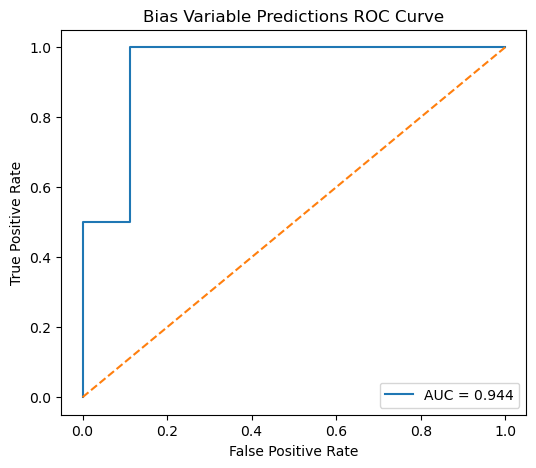

In [223]:
# Prediction Scores
y_scores = best_clf.decision_function(X_test_vec)
fpr, tpr, thresholds = roc_curve(y_test, y_scores)
auc = roc_auc_score(y_test, y_scores)

# Plot
plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f"AUC = {auc:.3f}")

plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Bias Variable Predictions ROC Curve")
plt.legend(loc="lower right")
plt.show()

### PROPERTY - best model even though nixing

In [224]:
TARGET = "property_complaint"
TEXT_COLUMN = "snippet_clean"

vectorizer = SentenceTransformer("all-MiniLM-L6-v2")
clf = LinearSVC(
        class_weight="balanced",
        random_state=123
    )

df_train = df.dropna(subset=[TARGET])

X = df_train[TEXT_COLUMN]
y = df_train[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=123,
    stratify=y
)

X_train_vec = vectorizer.encode(
            X_train.tolist(),
            show_progress_bar=False
        )

X_test_vec = vectorizer.encode(
            X_test.tolist(),
            show_progress_bar=False
        )

X_corpus = vectorizer.encode(
            df_corpus[TEXT_COLUMN].tolist(),
            show_progress_bar=False
        )

param_grid = {
    "C": [.01, .1, 1, 10, 100],
    "class_weight": ["balanced"],
    "loss": ["hinge", "squared_hinge"]
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=123
)

grid = GridSearchCV(
    estimator=clf,
    param_grid=param_grid,
    cv=cv,
    scoring={
        "f1": "f1",
        "macro_f1": "f1_macro",
        "precision": "precision",
        "recall": "recall"
    },
    refit="macro_f1",
    n_jobs=-1
)

grid.fit(X_train_vec, y_train)

best_clf = grid.best_estimator_

# Test set performance
y_pred = best_clf.predict(X_test_vec)

print("=== Best Model ===")
print("Best parameters:", grid.best_params_)

print("\n=== Cross-validation performance ===")
best_index = grid.best_index_
print("CV F1:", grid.cv_results_["mean_test_f1"][best_index])
print("CV Macro F1:", grid.cv_results_["mean_test_macro_f1"][best_index])
print("Precision:", grid.cv_results_["mean_test_precision"][best_index])
print("Recall:", grid.cv_results_["mean_test_recall"][best_index])


print("\n=== Held-out Test Performance ===")
print(classification_report(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))

print("\n=== Cohens Kappa ===")
print(cohen_kappa_score(y_test, y_pred))

# Predicting full corpus
df_corpus["property_pred"] = best_clf.predict(X_corpus)

print("\n=== Corpus Predictions ===")
print(df_corpus["property_pred"].value_counts())

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

=== Best Model ===
Best parameters: {'C': 1, 'class_weight': 'balanced', 'loss': 'squared_hinge'}

=== Cross-validation performance ===
CV F1: 0.2
CV Macro F1: 0.5773723100855588
Precision: 0.2
Recall: 0.2

=== Held-out Test Performance ===
              precision    recall  f1-score   support

           0       0.97      0.91      0.94        35
           1       0.40      0.67      0.50         3

    accuracy                           0.89        38
   macro avg       0.68      0.79      0.72        38
weighted avg       0.92      0.89      0.91        38

[[32  3]
 [ 1  2]]

=== Cohens Kappa ===
0.44525547445255476

=== Corpus Predictions ===
property_pred
0    1714
1     188
Name: count, dtype: int64


/Users/michelleupham/Desktop/Programs/anaconda3/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/Users/michelleupham/Desktop/Programs/anaconda3/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/Users/michelleupham/Desktop/Programs/anaconda3/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{m

In [225]:
dummy = DummyClassifier(strategy="stratified")
dummy.fit(X_train_vec, y_train)
dummy_pred = dummy.predict(X_test_vec)

model_scores = cross_val_score(
    best_clf,
    X_train_vec,
    y_train,
    cv=cv,
    scoring="f1_macro"
)

dummy_scores = cross_val_score(
    dummy,
    X_train_vec,
    y_train,
    cv=cv,
    scoring="f1_macro"
)

print(model_scores.mean())
print(dummy_scores.mean())

0.5773723100855588
0.6339050091889306


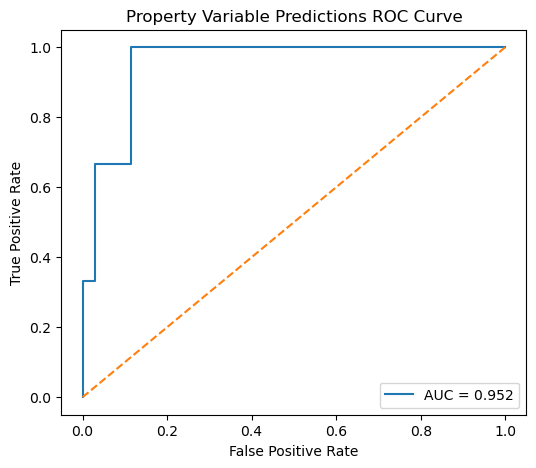

In [226]:
# Prediction Scores
y_scores = best_clf.decision_function(X_test_vec)
fpr, tpr, thresholds = roc_curve(y_test, y_scores)
auc = roc_auc_score(y_test, y_scores)

# Plot
plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f"AUC = {auc:.3f}")
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Property Variable Predictions ROC Curve")
plt.legend(loc="lower right")
plt.show()

### TRAFFIC

In [227]:
TARGET = "traffic_scenario"
TEXT_COLUMN = "complaint_clean"

vectorizer = SentenceTransformer("all-MiniLM-L6-v2")
clf = LinearSVC(
        class_weight="balanced",
        random_state=123
    )

df_train = df.dropna(subset=[TARGET])

X = df_train[TEXT_COLUMN]
y = df_train[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=123,
    stratify=y
)

X_train_vec = vectorizer.encode(
            X_train.tolist(),
            show_progress_bar=False
        )

X_test_vec = vectorizer.encode(
            X_test.tolist(),
            show_progress_bar=False
        )

X_corpus = vectorizer.encode(
            df_corpus[TEXT_COLUMN].tolist(),
            show_progress_bar=False
        )

param_grid = {
    "C": [.01, .1, 1, 10, 100],
    "class_weight": ["balanced"],
    "loss": ["hinge", "squared_hinge"]
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=123
)

grid = GridSearchCV(
    estimator=clf,
    param_grid=param_grid,
    cv=cv,
    scoring={
        "f1": "f1",
        "macro_f1": "f1_macro",
        "precision": "precision",
        "recall": "recall"
    },
    refit="macro_f1",
    n_jobs=-1
)

grid.fit(X_train_vec, y_train)

best_clf = grid.best_estimator_

# Test set performance
y_pred = best_clf.predict(X_test_vec)

print("=== Best Model ===")
print("Best parameters:", grid.best_params_)

print("\n=== Cross-validation performance ===")
best_index = grid.best_index_
print("CV F1:", grid.cv_results_["mean_test_f1"][best_index])
print("CV Macro F1:", grid.cv_results_["mean_test_macro_f1"][best_index])
print("Precision:", grid.cv_results_["mean_test_precision"][best_index])
print("Recall:", grid.cv_results_["mean_test_recall"][best_index])


print("\n=== Held-out Test Performance ===")
print(classification_report(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))

print("\n=== Cohens Kappa ===")
print(cohen_kappa_score(y_test, y_pred))

# Predicting full corpus
df_corpus["traffic_pred"] = best_clf.predict(X_corpus)

print("\n=== Corpus Predictions ===")
print(df_corpus["traffic_pred"].value_counts())

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

=== Best Model ===
Best parameters: {'C': 1, 'class_weight': 'balanced', 'loss': 'hinge'}

=== Cross-validation performance ===
CV F1: 0.6449417249417249
CV Macro F1: 0.7793067064647612
Precision: 0.6154761904761905
Recall: 0.7066666666666667

=== Held-out Test Performance ===
              precision    recall  f1-score   support

           0       0.94      0.94      0.94        31
           1       0.71      0.71      0.71         7

    accuracy                           0.89        38
   macro avg       0.82      0.82      0.82        38
weighted avg       0.89      0.89      0.89        38

[[29  2]
 [ 2  5]]

=== Cohens Kappa ===
0.6497695852534562

=== Corpus Predictions ===
traffic_pred
0    1406
1     496
Name: count, dtype: int64


In [228]:
dummy = DummyClassifier(strategy="stratified")
dummy.fit(X_train_vec, y_train)
dummy_pred = dummy.predict(X_test_vec)

model_scores = cross_val_score(
    best_clf,
    X_train_vec,
    y_train,
    cv=cv,
    scoring="f1_macro"
)

dummy_scores = cross_val_score(
    dummy,
    X_train_vec,
    y_train,
    cv=cv,
    scoring="f1_macro"
)

print(model_scores.mean())
print(dummy_scores.mean())

0.7793067064647612
0.45543427770972145


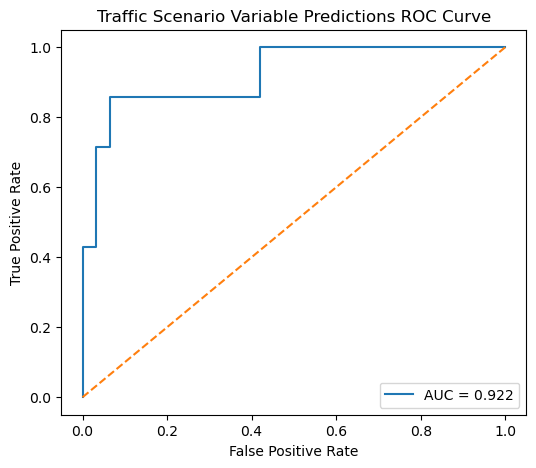

In [229]:
# Prediction Scores
y_scores = best_clf.decision_function(X_test_vec)
fpr, tpr, thresholds = roc_curve(y_test, y_scores)
auc = roc_auc_score(y_test, y_scores)

# Plot
plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f"AUC = {auc:.3f}")
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Traffic Scenario Variable Predictions ROC Curve")
plt.legend(loc="lower right")
plt.show()

### MENTAL HEALTH

In [230]:
TARGET = "mental_health"
TEXT_COLUMN = "snippet_clean"

vectorizer = SentenceTransformer("all-MiniLM-L6-v2")
clf = LinearSVC(
        class_weight="balanced",
        random_state=123
    )

df_train = df.dropna(subset=[TARGET])

X = df_train[TEXT_COLUMN]
y = df_train[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=123,
    stratify=y
)

X_train_vec = vectorizer.encode(
            X_train.tolist(),
            show_progress_bar=False
        )

X_test_vec = vectorizer.encode(
            X_test.tolist(),
            show_progress_bar=False
        )

X_corpus = vectorizer.encode(
            df_corpus[TEXT_COLUMN].tolist(),
            show_progress_bar=False
        )

param_grid = {
    "C": [.01, .1, 1, 10, 100],
    "class_weight": ["balanced"],
    "loss": ["hinge", "squared_hinge"]
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=123
)

grid = GridSearchCV(
    estimator=clf,
    param_grid=param_grid,
    cv=cv,
    scoring={
        "f1": "f1",
        "macro_f1": "f1_macro",
        "precision": "precision",
        "recall": "recall"
    },
    refit="macro_f1",
    n_jobs=-1
)

grid.fit(X_train_vec, y_train)

best_clf = grid.best_estimator_

# Test set performance
y_pred = best_clf.predict(X_test_vec)

print("=== Best Model ===")
print("Best parameters:", grid.best_params_)

print("\n=== Cross-validation performance ===")
best_index = grid.best_index_
print("CV F1:", grid.cv_results_["mean_test_f1"][best_index])
print("CV Macro F1:", grid.cv_results_["mean_test_macro_f1"][best_index])
print("Precision:", grid.cv_results_["mean_test_precision"][best_index])
print("Recall:", grid.cv_results_["mean_test_recall"][best_index])


print("\n=== Held-out Test Performance ===")
print(classification_report(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))

print("\n=== Cohens Kappa ===")
print(cohen_kappa_score(y_test, y_pred))

# Predicting full corpus
df_corpus["mh_pred"] = best_clf.predict(X_corpus)

print("\n=== Corpus Predictions ===")
print(df_corpus["mh_pred"].value_counts())

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

=== Best Model ===
Best parameters: {'C': 1, 'class_weight': 'balanced', 'loss': 'hinge'}

=== Cross-validation performance ===
CV F1: 0.4444444444444445
CV Macro F1: 0.6963922818299344
Precision: 0.425
Recall: 0.6

=== Held-out Test Performance ===
              precision    recall  f1-score   support

           0       0.97      0.94      0.96        36
           1       0.33      0.50      0.40         2

    accuracy                           0.92        38
   macro avg       0.65      0.72      0.68        38
weighted avg       0.94      0.92      0.93        38

[[34  2]
 [ 1  1]]

=== Cohens Kappa ===
0.3595505617977528

=== Corpus Predictions ===
mh_pred
0    1829
1      73
Name: count, dtype: int64


/Users/michelleupham/Desktop/Programs/anaconda3/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/Users/michelleupham/Desktop/Programs/anaconda3/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/Users/michelleupham/Desktop/Programs/anaconda3/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{m

In [231]:
dummy = DummyClassifier(strategy="stratified")
dummy.fit(X_train_vec, y_train)
dummy_pred = dummy.predict(X_test_vec)

model_scores = cross_val_score(
    best_clf,
    X_train_vec,
    y_train,
    cv=cv,
    scoring="f1_macro"
)

dummy_scores = cross_val_score(
    dummy,
    X_train_vec,
    y_train,
    cv=cv,
    scoring="f1_macro"
)

print(model_scores.mean())
print(dummy_scores.mean())

0.6963922818299344
0.47000796360665936


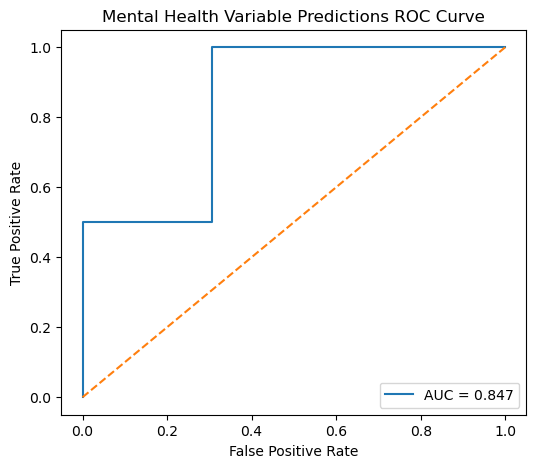

In [232]:
# Prediction Scores
y_scores = best_clf.decision_function(X_test_vec)
fpr, tpr, thresholds = roc_curve(y_test, y_scores)
auc = roc_auc_score(y_test, y_scores)

# ROC Curve Plot
plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f"AUC = {auc:.3f}")
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Mental Health Variable Predictions ROC Curve")
plt.legend(loc="lower right")
plt.show()

### DEMEANOR

In [233]:
TARGET = "demeanor_complaint"
TEXT_COLUMN = "complaint_clean"

vectorizer = SentenceTransformer("all-MiniLM-L6-v2")
clf = LinearSVC(
        class_weight="balanced",
        random_state=123,
        max_iter=3000
    )

df_train = df.dropna(subset=[TARGET])

X = df_train[TEXT_COLUMN]
y = df_train[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=123,
    stratify=y
)

X_train_vec = vectorizer.encode(
            X_train.tolist(),
            show_progress_bar=False
        )

X_test_vec = vectorizer.encode(
            X_test.tolist(),
            show_progress_bar=False
        )

X_corpus = vectorizer.encode(
            df_corpus[TEXT_COLUMN].tolist(),
            show_progress_bar=False
        )

param_grid = {
    "C": [.01, .1, 1, 10, 100],
    "class_weight": ["balanced"],
    "loss": ["hinge", "squared_hinge"]
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=123
)

grid = GridSearchCV(
    estimator=clf,
    param_grid=param_grid,
    cv=cv,
    scoring={
        "f1": "f1",
        "macro_f1": "f1_macro",
        "precision": "precision",
        "recall": "recall"
    },
    refit="macro_f1",
    n_jobs=-1
)

grid.fit(X_train_vec, y_train)

best_clf = grid.best_estimator_

# Test set performance
y_pred = best_clf.predict(X_test_vec)

print("=== Best Model ===")
print("Best parameters:", grid.best_params_)

print("\n=== Cross-validation performance ===")
best_index = grid.best_index_
print("CV F1:", grid.cv_results_["mean_test_f1"][best_index])
print("CV Macro F1:", grid.cv_results_["mean_test_macro_f1"][best_index])
print("Precision:", grid.cv_results_["mean_test_precision"][best_index])
print("Recall:", grid.cv_results_["mean_test_recall"][best_index])


print("\n=== Held-out Test Performance ===")
print(classification_report(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))

print("\n=== Cohens Kappa ===")
print(cohen_kappa_score(y_test, y_pred))

# Predicting full corpus
df_corpus["demeanor_pred"] = best_clf.predict(X_corpus)

print("\n=== Corpus Predictions ===")
print(df_corpus["demeanor_pred"].value_counts())

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

=== Best Model ===
Best parameters: {'C': 10, 'class_weight': 'balanced', 'loss': 'hinge'}

=== Cross-validation performance ===
CV F1: 0.6384657295412445
CV Macro F1: 0.7044736402553001
Precision: 0.6426874003189792
Recall: 0.6636363636363636

=== Held-out Test Performance ===
              precision    recall  f1-score   support

           0       0.77      0.71      0.74        24
           1       0.56      0.64      0.60        14

    accuracy                           0.68        38
   macro avg       0.67      0.68      0.67        38
weighted avg       0.70      0.68      0.69        38

[[17  7]
 [ 5  9]]

=== Cohens Kappa ===
0.34104046242774566

=== Corpus Predictions ===
demeanor_pred
0    1169
1     733
Name: count, dtype: int64


In [234]:
dummy = DummyClassifier(strategy="stratified")
dummy.fit(X_train_vec, y_train)
dummy_pred = dummy.predict(X_test_vec)

model_scores = cross_val_score(
    best_clf,
    X_train_vec,
    y_train,
    cv=cv,
    scoring="f1_macro"
)

dummy_scores = cross_val_score(
    dummy,
    X_train_vec,
    y_train,
    cv=cv,
    scoring="f1_macro"
)

print(model_scores.mean())
print(dummy_scores.mean())

0.7044736402553001
0.42878032109097575


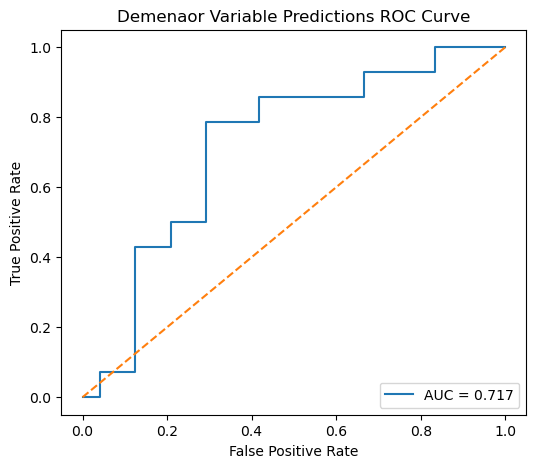

In [235]:
# Prediction Scores 
y_scores = best_clf.decision_function(X_test_vec)
fpr, tpr, thresholds = roc_curve(y_test, y_scores)
auc = roc_auc_score(y_test, y_scores)

# Plotting the ROC Curve
plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f"AUC = {auc:.3f}")
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Demenaor Variable Predictions ROC Curve")
plt.legend(loc="lower right")
plt.show()

### REGULATORY

In [236]:
TARGET = "regulatory_complaint"
TEXT_COLUMN = "complaint_clean"

vectorizer = SentenceTransformer("all-MiniLM-L6-v2")
clf = LinearSVC(
        class_weight="balanced",
        random_state=123
    )

df_train = df.dropna(subset=[TARGET])

X = df_train[TEXT_COLUMN]
y = df_train[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=123,
    stratify=y
)

X_train_vec = vectorizer.encode(
            X_train.tolist(),
            show_progress_bar=False
        )

X_test_vec = vectorizer.encode(
            X_test.tolist(),
            show_progress_bar=False
        )

X_corpus = vectorizer.encode(
            df_corpus[TEXT_COLUMN].tolist(),
            show_progress_bar=False
        )

param_grid = {
    "C": [.01, .1, 1, 10, 100],
    "class_weight": ["balanced"],
    "loss": ["hinge", "squared_hinge"]
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=123
)

grid = GridSearchCV(
    estimator=clf,
    param_grid=param_grid,
    cv=cv,
    scoring={
        "f1": "f1",
        "macro_f1": "f1_macro",
        "precision": "precision",
        "recall": "recall"
    },
    refit="macro_f1",
    n_jobs=-1
)

grid.fit(X_train_vec, y_train)

best_clf = grid.best_estimator_

# Test set performance
y_pred = best_clf.predict(X_test_vec)

print("=== Best Model ===")
print("Best parameters:", grid.best_params_)

print("\n=== Cross-validation performance ===")
best_index = grid.best_index_
print("CV F1:", grid.cv_results_["mean_test_f1"][best_index])
print("CV Macro F1:", grid.cv_results_["mean_test_macro_f1"][best_index])
print("Precision:", grid.cv_results_["mean_test_precision"][best_index])
print("Recall:", grid.cv_results_["mean_test_recall"][best_index])


print("\n=== Held-out Test Performance ===")
print(classification_report(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))

print("\n=== Cohens Kappa ===")
print(cohen_kappa_score(y_test, y_pred))

# Predict full corpus
df_corpus["regulatory_pred"] = best_clf.predict(X_corpus)

print("\n=== Corpus Predictions ===")
print(df_corpus["regulatory_pred"].value_counts())

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

=== Best Model ===
Best parameters: {'C': 10, 'class_weight': 'balanced', 'loss': 'hinge'}

=== Cross-validation performance ===
CV F1: 0.4212121212121212
CV Macro F1: 0.6485920242222764
Precision: 0.4800000000000001
Recall: 0.38

=== Held-out Test Performance ===
              precision    recall  f1-score   support

           0       0.91      0.97      0.94        31
           1       0.80      0.57      0.67         7

    accuracy                           0.89        38
   macro avg       0.85      0.77      0.80        38
weighted avg       0.89      0.89      0.89        38

[[30  1]
 [ 3  4]]

=== Cohens Kappa ===
0.6062176165803108

=== Corpus Predictions ===
regulatory_pred
0    1604
1     298
Name: count, dtype: int64


In [237]:
dummy = DummyClassifier(strategy="stratified")
dummy.fit(X_train_vec, y_train)
dummy_pred = dummy.predict(X_test_vec)

model_scores = cross_val_score(
    best_clf,
    X_train_vec,
    y_train,
    cv=cv,
    scoring="f1_macro"
)

dummy_scores = cross_val_score(
    dummy,
    X_train_vec,
    y_train,
    cv=cv,
    scoring="f1_macro"
)

print(model_scores.mean())
print(dummy_scores.mean())

0.6485920242222764
0.5671706118344774


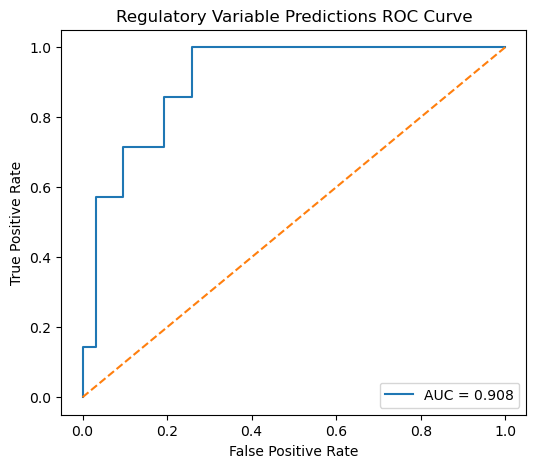

In [238]:
# Prediction Scores
y_scores = best_clf.decision_function(X_test_vec)
fpr, tpr, thresholds = roc_curve(y_test, y_scores)
auc = roc_auc_score(y_test, y_scores)

# Plotting the ROC Curve
plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f"AUC = {auc:.3f}")
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Regulatory Variable Predictions ROC Curve")
plt.legend(loc="lower right")
plt.show()

## Nonconcurrence

In [239]:
non = pd.read_excel("nonconcurrence.xlsx", header=0)

In [240]:
df_corpus.loc[df_corpus["case_number"].isin(non.case_number), "nonconcurrence_flag"] = 1
df_corpus.loc[~df_corpus["case_number"].isin(non.case_number), "nonconcurrence_flag"] = 0

In [241]:
non.gender_officer.value_counts()

gender_officer
m    51
f    19
Name: count, dtype: int64

In [242]:
f_cols = [c for c in df_corpus.columns if c.startswith("f_")]

unique_values = (
    pd.Series(df_corpus[f_cols].values.ravel())
      .dropna()
      .unique()
)

print(sorted(unique_values))

['ADMINISTRATIVELY', 'Administratively Close', 'Administratively Closed', 'Administratively Closing', 'Exonerated', 'Not Sustained', 'SUSTAINED', 'Sustained', 'Sustained Violation Not Based on Original', 'Sustained Violation Not Based on Original Complaint', 'UNFOUNDED', 'Unfounded']


In [243]:
# Standardizing the findings texts
mapping = {
    "ADMINISTRATIVELY": "Administratively Closed",
    "Administratively Close": "Administratively Closed",
    "Administratively Closed": "Administratively Closed",
    "Administratively Closing": "Administratively Closed",

    "Exonerated": "Exonerated",

    "Not Sustained": "Not Sustained",

    "SUSTAINED": "Sustained",
    "Sustained": "Sustained",
    "Sustained Violation Not Based on Original": "Sustained NBOOC",
    "Sustained Violation Not Based on Original Complaint": "Sustained NBOOC",

    "UNFOUNDED": "Unfounded",
    "Unfounded": "Unfounded",
}

f_cols = [c for c in df_corpus.columns if c.startswith("f_")]

df_corpus[f_cols] = df_corpus[f_cols].replace(mapping)

In [244]:
mask = df_corpus[f_cols].isin(["Sustained", "Sustained NBOOC"]).any(axis=1)
# getting "other_finding" variable (any finding that is "sustained")
df_corpus.loc[mask, "other_finding"] = 1
df_corpus.loc[~mask, "other_finding"] = 0

In [245]:
mask_finding = (df_corpus["other_finding"] == 1)
mask_nonconcurrence = (df_corpus["nonconcurrence_flag"] == 1)
mask = (
    (df_corpus["other_finding"] == 1)
    & (df_corpus["nonconcurrence_flag"] == 0)
)
print(f"Percent Sustained: {100 * mask_finding.mean():.2f}%")
print(f"Percent Nonconcurrence: {100 * mask_nonconcurrence.mean():.2f}%")
print(f"Percent Sustained and NO nonconcurrence (findings of CPOA applied 100%): {100 * mask.mean():.2f}%")

Percent Sustained: 20.72%
Percent Nonconcurrence: 3.68%
Percent Sustained and NO nonconcurrence (findings of CPOA applied 100%): 17.88%


In [246]:
len(df_corpus[mask])

340

In [247]:
df_corpus = df_corpus.drop(columns='property_pred')

In [248]:
pred_cols = [col for col in df_corpus.columns if col.endswith("_pred")]
df_corpus["nothing_pred"] = np.where(
    (df_corpus[pred_cols] == 0).all(axis=1),
    1,
    0
)

In [249]:
percent_missing = df_corpus.isnull().mean() * 100
print(percent_missing)

id_pre                   0.000000
id_post                  0.000000
snippet                  0.000000
case_number              0.000000
letter_date              0.000000
date_inves_complete     32.018927
incident_date           54.942166
complaint_date          47.791798
officer_involved        32.597266
complaint_clean          0.000000
findings_clean           0.000000
f_1                      0.998948
f_2                     57.150368
f_3                     95.425868
f_4                     99.316509
f_5                    100.000000
snippet_clean            0.000000
bias_pred                0.000000
traffic_pred             0.000000
mh_pred                  0.000000
demeanor_pred            0.000000
regulatory_pred          0.000000
nonconcurrence_flag      0.000000
other_finding            0.000000
nothing_pred             0.000000
dtype: float64


In [250]:
df_corpus.to_csv("post_prediction_corpus.csv", index=False)

In [251]:
df_corpus.columns

Index(['id_pre', 'id_post', 'snippet', 'case_number', 'letter_date',
       'date_inves_complete', 'incident_date', 'complaint_date',
       'officer_involved', 'complaint_clean', 'findings_clean', 'f_1', 'f_2',
       'f_3', 'f_4', 'f_5', 'snippet_clean', 'bias_pred', 'traffic_pred',
       'mh_pred', 'demeanor_pred', 'regulatory_pred', 'nonconcurrence_flag',
       'other_finding', 'nothing_pred'],
      dtype='object')

## Evaluating Regex Captured Variables

In [252]:
merged = df.merge(
    df_all,
    on="id_post",
    suffixes=("_hand", "_regex")
)

In [253]:
merged["letter_date_hand"] = pd.to_datetime(merged["letter_date_hand"], errors="coerce").dt.normalize()

merged["complaint_date_hand"] = pd.to_datetime(merged["complaint_date_hand"], 
                                          format="mixed", 
                                          errors="coerce").dt.normalize()

merged["incident_date_hand"] = pd.to_datetime(merged["incident_date_hand"], 
                                         format="mixed", 
                                         errors="coerce").dt.normalize()
merged["investigation_complete_date"] = pd.to_datetime(merged["investigation_complete_date"], errors="coerce").dt.normalize()


/var/folders/2l/nhkr05_11xl7646nkk74q5640000gn/T/ipykernel_88011/1610595764.py:1: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  merged["letter_date_hand"] = pd.to_datetime(merged["letter_date_hand"], errors="coerce").dt.normalize()
/var/folders/2l/nhkr05_11xl7646nkk74q5640000gn/T/ipykernel_88011/1610595764.py:10: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  merged["investigation_complete_date"] = pd.to_datetime(merged["investigation_complete_date"], errors="coerce").dt.normalize()


In [254]:
f_cols = [c for c in merged.columns if (c.startswith("f_") & c.endswith("regex"))]

unique_values = (
    pd.Series(merged[f_cols].values.ravel())
      .dropna()
      .unique()
)

print(sorted(unique_values))

['ADMINISTRATIVELY', 'Administratively Close', 'Administratively Closed', 'Administratively Closing', 'Exonerated', 'Not Sustained', 'Sustained', 'Sustained Violation Not Based on Original', 'Unfounded']


In [255]:
mapping = {
    "ADMINISTRATIVELY": "Administratively Closed",
    "Administratively Close": "Administratively Closed",
    "Administratively Closed": "Administratively Closed",
    "Administratively Closing": "Administratively Closed",

    "Exonerated": "Exonerated",

    "Not Sustained": "Not Sustained",

    "SUSTAINED": "Sustained",
    "Sustained": "Sustained",
    "Sustained Violation Not Based on Original": "Sustained NBOOC",
    "Sustained Violation Not Based on Original Complaint": "Sustained NBOOC",

    "UNFOUNDED": "Unfounded",
    "Unfounded": "Unfounded",
}

merged[f_cols] = merged[f_cols].replace(mapping)

/var/folders/2l/nhkr05_11xl7646nkk74q5640000gn/T/ipykernel_88011/559133544.py:20: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  merged[f_cols] = merged[f_cols].replace(mapping)


In [256]:
mask = merged[f_cols].isin(["Sustained", "Sustained NBOOC"]).any(axis=1)

merged.loc[mask, "other_finding_regex"] = 1
merged.loc[~mask, "other_finding_regex"] = 0

In [257]:
mask_finding = (merged["other_finding_regex"] == 1)
mask_nonconcurrence = (merged["nonconcurrence_flag"] == 1)
mask = (
    (merged["other_finding_regex"] == 1)
    & (merged["nonconcurrence_flag"] == 0)
)

In [258]:
merged.columns
# Note that "investigation_complete_date" column == HAND
# Whereas "date_inves_complete" == REGEX

Index(['Unnamed: 0', 'filename', 'snippet_raw', 'Location', 'letter_date_hand',
       'incident_date_hand', 'complaint_date_hand',
       'investigation_complete_date', 'jurisdiction_flag', 'duplicative_flag',
       'withdrawal_flag', 'traffic_scenario', 'discipline_recommended',
       'property_complaint', 'property_finding', 'bias_complaint',
       'bias_finding', 'demeanor_complaint', 'demeanor_finding',
       'regulatory_complaint', 'regulatory_finding', 'weapon_complaint',
       'weapon_finding', 'other_finding', 'mental_health',
       'nonconcurrence_flag', 'force_review_board', 'shelly_notes',
       'filename_ev', 'pattern', 'snippet_hand', 'case_number_hand',
       'letter_date_ev', 'incident_date_ev', 'complaint_date_ev',
       'disagreement', 'complaint', 'investigation', 'findings', 'f_1_hand',
       'f_2_hand', 'f_3_hand', 'f_4_hand', 'f_5_hand', 'f_6', 'f_7', 'f_8',
       'f_9', 'f_10', 'f_11', 'f_12', 'f_13', 'f_14', 'f_15', 'f_16', 'f_17',
       'f_18', 'f_1

In [259]:
cols = ["id_post", "id_pre_regex", "id_pre_hand",
        "case_number_hand", "case_number_regex",
        "letter_date_hand", "letter_date_regex",
        "complaint_date_hand", "complaint_date_regex",
        "incident_date_hand", "incident_date_regex",
        "other_finding", "other_finding_regex",
        "investigation_complete_date", "date_inves_complete"]

comparison = merged[cols].copy()

In [260]:
# Computing date differences
comparison["complaint_date_diff"] = (comparison["complaint_date_hand"] - comparison["complaint_date_regex"]).dt.days
comparison["incident_date_diff"] = (comparison["incident_date_hand"] - comparison["incident_date_regex"]).dt.days
comparison["letter_date_diff"] = (comparison["letter_date_hand"] - comparison["letter_date_regex"]).dt.days
comparison["ic_date_diff"] = (comparison["investigation_complete_date"] - comparison["date_inves_complete"]).dt.days

In [261]:
comparison["finding_diff"] = (comparison["other_finding"] - comparison["other_finding_regex"])
# Differences here could be explained by the lack of clear findings in written language (checkboxes)

In [262]:
# all case numbers exactly the same
(comparison["case_number_hand"] == comparison["case_number_regex"]).mean() * 100

np.float64(100.0)

In [263]:
percent_missing = comparison.complaint_date_hand.isnull().mean() * 100
print(percent_missing)

46.31578947368421


In [264]:
comparison["finding_diff"].describe()

count    190.000000
mean      -0.005263
std        0.218154
min       -1.000000
25%        0.000000
50%        0.000000
75%        0.000000
max        1.000000
Name: finding_diff, dtype: float64

In [265]:
comparison["incident_date_diff"].describe()

count     78.000000
mean       3.948718
std       34.537725
min       -4.000000
25%        0.000000
50%        0.000000
75%        0.000000
max      305.000000
Name: incident_date_diff, dtype: float64

In [266]:
comparison["complaint_date_diff"].describe()

count    93.0
mean      0.0
std       0.0
min       0.0
25%       0.0
50%       0.0
75%       0.0
max       0.0
Name: complaint_date_diff, dtype: float64

In [267]:
comparison["ic_date_diff"].describe()

count    127.0
mean       0.0
std        0.0
min        0.0
25%        0.0
50%        0.0
75%        0.0
max        0.0
Name: ic_date_diff, dtype: float64

In [268]:
len(comparison[comparison["finding_diff"]!= 0 & comparison["other_finding"].notna()])
# 10 rows of 190 that disagree on whether or not the CPOA held a finding against the officer.

9

In [269]:
comparison[comparison["complaint_date_diff"].notna() & comparison["complaint_date_diff"] != 0]

,id_post,id_pre_regex,id_pre_hand,case_number_hand,case_number_regex,letter_date_hand,letter_date_regex,complaint_date_hand,complaint_date_regex,incident_date_hand,incident_date_regex,other_finding,other_finding_regex,investigation_complete_date,date_inves_complete,complaint_date_diff,incident_date_diff,letter_date_diff,ic_date_diff,finding_diff


In [270]:
comparison[comparison["letter_date_diff"].notna() & comparison["letter_date_diff"] != 0]

,id_post,id_pre_regex,id_pre_hand,case_number_hand,case_number_regex,letter_date_hand,letter_date_regex,complaint_date_hand,complaint_date_regex,incident_date_hand,incident_date_regex,other_finding,other_finding_regex,investigation_complete_date,date_inves_complete,complaint_date_diff,incident_date_diff,letter_date_diff,ic_date_diff,finding_diff


In [271]:
len(comparison[comparison["incident_date_diff"].notna() & comparison["incident_date_diff"] != 0])
# 4 rows with differences in incident date.

4

In [272]:
comparison[comparison["ic_date_diff"].notna() & comparison["ic_date_diff"] != 0]

,id_post,id_pre_regex,id_pre_hand,case_number_hand,case_number_regex,letter_date_hand,letter_date_regex,complaint_date_hand,complaint_date_regex,incident_date_hand,incident_date_regex,other_finding,other_finding_regex,investigation_complete_date,date_inves_complete,complaint_date_diff,incident_date_diff,letter_date_diff,ic_date_diff,finding_diff


## Running Statistical Analyses

See information in Stats.ipynb